In [147]:
from src.features import (
    add_basic_features,
    fit_access_params,
    access_components,
    add_access_features,
    fit_density_params,
    add_density_features,
    fit_bin_edges,
    add_access_class,
)

print("All eight feature-engineering functions imported successfully!")

All eight feature-engineering functions imported successfully!


In [148]:
import inspect

functions = [
    add_basic_features,
    fit_access_params,
    access_components,
    add_access_features,
    fit_density_params,
    add_density_features,
    fit_bin_edges,
    add_access_class,
]

for func in functions:
    print(f"{func.__name__}{inspect.signature(func)}")

add_basic_features(d)
fit_access_params(train, cols)
access_components(d, params)
add_access_features(d, params, weights)
fit_density_params(train, count_bases)
add_density_features(d, params, count_bases)
fit_bin_edges(train, score)
add_access_class(d, edges, score)


In [149]:
print("Final model feature count:", len(FINAL_FEATURES))
print("\nExpected model features:")
for feature in FINAL_FEATURES:
    print("-", feature)
    

Final model feature count: 15

Expected model features:
- bedroom_num
- bathroom_num
- balcony_num
- floor_num
- total_floor
- total_landmark_count
- area_sqft
- property_type
- owntype
- furnish
- facing
- age
- locality_grouped
- latitude
- longitude


In [150]:
import src.features as features

print("Feature module:", features.__file__)

expected_functions = [
    "add_basic_features",
    "fit_access_params",
    "access_components",
    "add_access_features",
    "fit_density_params",
    "add_density_features",
    "fit_bin_edges",
    "add_access_class",
]

for name in expected_functions:
    print(f"{name}: {callable(getattr(features, name, None))}")

Feature module: D:\real-estate-price-prediction\src\features.py
add_basic_features: True
fit_access_params: True
access_components: True
add_access_features: True
fit_density_params: True
add_density_features: True
fit_bin_edges: True
add_access_class: True


In [151]:
test_df = full.head(5).copy()

print("Before:", test_df.shape)

test_result = add_basic_features(test_df)

print("After:", test_result.shape if hasattr(test_result, "shape") else type(test_result))
print("\nColumns:")
print(test_result.columns.tolist() if hasattr(test_result, "columns") else "Function returned no DataFrame")

Before: (5, 45)
After: (5, 45)

Columns:
['prop_id', 'latitude', 'longitude', 'property_type', 'owntype', 'bedroom_num', 'bathroom_num', 'balcony_num', 'furnish', 'facing', 'age', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'area_is_carpet', 'locality_grouped', 'price_lakhs', 'log_price', 'dist_railway_km', 'dist_bus_km', 'dist_school_km', 'dist_hospital_km', 'dist_mall_km', 'dist_highway_km', 'dist_mainroad_km', 'n_school_1km', 'n_school_2km', 'n_hospital_1km', 'n_hospital_2km', 'n_bus_1km', 'n_bus_2km', 'n_mall_1km', 'n_mall_2km', 'bed_bath_ratio', 'total_rooms', 'area_per_bedroom', 'floor_ratio', 'access_plain', 'access_weighted', 'amenity_density_1km', 'n_total_1km', 'amenity_density_2km', 'n_total_2km', 'access_class']


In [152]:
from pathlib import Path
import joblib
import json

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
MODEL_PATH = PROJECT_DIR / "models" / "final_price_model.joblib"
METADATA_PATH = PROJECT_DIR / "models" / "final_model_metadata.json"

# Check files
print("Model exists:", MODEL_PATH.exists())
print("Metadata exists:", METADATA_PATH.exists())

# Load model
final_model = joblib.load(MODEL_PATH)

print("\nModel type:", type(final_model).__name__)

# Inspect expected input features
if hasattr(final_model, "feature_names_in_"):
    model_features = list(final_model.feature_names_in_)
    print("\nExpected feature count:", len(model_features))
    print("Expected features:", model_features)
else:
    print("\nThe top-level model does not expose feature_names_in_.")
    print("We will inspect the pipeline steps next if needed.")

Model exists: True
Metadata exists: True

Model type: Pipeline

Expected feature count: 15
Expected features: ['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped', 'latitude', 'longitude']


In [146]:
import sys
from pathlib import Path

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

print("Project directory added to Python path.")
print("src folder contents:", list((PROJECT_DIR / "src").iterdir()))

Project directory added to Python path.
src folder contents: [WindowsPath('D:/real-estate-price-prediction/src/features.py'), WindowsPath('D:/real-estate-price-prediction/src/location_features.py'), WindowsPath('D:/real-estate-price-prediction/src/preprocess.py'), WindowsPath('D:/real-estate-price-prediction/src/__pycache__')]


In [1]:
import json
import os

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
os.makedirs("../models", exist_ok=True)
os.makedirs("../reports/figures", exist_ok=True)

print("Required directories are ready.")

Required directories are ready.


In [3]:
print("Models directory exists:", os.path.isdir("../models"))
print("Figures directory exists:", os.path.isdir("../reports/figures"))

Models directory exists: True
Figures directory exists: True


In [4]:
input_path = "../data/processed/clean_v3_location.csv"

df = pd.read_csv(input_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (7457, 34)

First five rows:


,prop_id,latitude,longitude,property_type,owntype,bedroom_num,bathroom_num,balcony_num,furnish,facing,...,dist_highway_km,dist_mainroad_km,n_school_1km,n_school_2km,n_hospital_1km,n_hospital_2km,n_bus_1km,n_bus_2km,n_mall_1km,n_mall_2km
0,O71585872,28.406534,76.962792,Residential Apartment,1,4.0,4,4.0,4,1,...,0.006102,0.006102,0,0,0,0,0,0,0,0
1,T71585466,28.388907,76.951328,Residential Apartment,1,4.0,4,3.0,4,1,...,0.005423,0.005423,0,0,0,0,0,0,0,0
2,I71493958,28.518677,77.015115,Residential Apartment,1,3.0,3,3.0,4,0,...,0.004921,0.004921,0,4,0,1,0,1,0,3
3,X71361930,28.478440,76.986110,Residential Apartment,1,3.0,4,4.0,4,2,...,0.022995,0.022995,0,3,0,3,0,4,0,2
4,N71483500,28.416400,77.012620,Residential Apartment,1,2.0,2,3.0,2,3,...,0.044808,0.044808,3,3,0,0,0,8,0,1


In [5]:
print("Columns in the dataset:")
for col in df.columns:
    print(col)

Columns in the dataset:
prop_id
latitude
longitude
property_type
owntype
bedroom_num
bathroom_num
balcony_num
furnish
facing
age
floor_num
total_floor
total_landmark_count
area_sqft
area_is_carpet
locality_grouped
price_lakhs
log_price
dist_railway_km
dist_bus_km
dist_school_km
dist_hospital_km
dist_mall_km
dist_highway_km
dist_mainroad_km
n_school_1km
n_school_2km
n_hospital_1km
n_hospital_2km
n_bus_1km
n_bus_2km
n_mall_1km
n_mall_2km


In [6]:
required_columns = [
    "price_lakhs",
    "owntype",
    "furnish",
    "facing",
    "age"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required columns are present.")

All required columns are present.


In [7]:
print("Price data type:", df["price_lakhs"].dtype)

print("\nMissing prices:", df["price_lakhs"].isna().sum())

print("\nPrice summary:")
display(df["price_lakhs"].describe())

print("\nNumber of zero or negative prices:",
      (df["price_lakhs"] <= 0).sum())

Price data type: float64

Missing prices: 0

Price summary:


count    7457.000000
mean      347.218318
std       307.582371
min       100.000000
25%       175.000000
50%       250.000000
75%       405.000000
max      4500.000000
Name: price_lakhs, dtype: float64


Number of zero or negative prices: 0


In [8]:
cat_codes = ["owntype", "furnish", "facing", "age"]
df[cat_codes] = df[cat_codes].astype(str)

In [9]:
cat_codes = ["owntype", "furnish", "facing", "age"]

print("Data types before conversion:")
display(df[cat_codes].dtypes.to_frame("dtype"))

df[cat_codes] = df[cat_codes].astype("string")

print("\nData types after conversion:")
display(df[cat_codes].dtypes.to_frame("dtype"))

Data types before conversion:


,dtype
owntype,str
furnish,str
facing,str
age,str



Data types after conversion:


,dtype
owntype,string
furnish,string
facing,string
age,string


In [10]:
for col in cat_codes:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(20))


owntype:
owntype
1    7375
2      43
3      31
4       8
Name: count, dtype: int64[pyarrow]

furnish:
furnish
4    5764
2     940
1     509
0     244
Name: count, dtype: int64[pyarrow]

facing:
facing
5    2500
3    1728
1    1045
0     833
4     468
6     269
7     262
2     181
8     171
Name: count, dtype: int64[pyarrow]

age:
age
1    2447
6    2059
5    1255
2    1157
3     538
0       1
Name: count, dtype: int64[pyarrow]


In [11]:
df["price_lakhs"] = pd.to_numeric(
    df["price_lakhs"],
    errors="coerce"
)

if df["price_lakhs"].isna().any():
    raise ValueError(
        "price_lakhs contains missing or non-numeric values."
    )

if (df["price_lakhs"] <= 0).any():
    raise ValueError(
        "price_lakhs contains zero or negative values."
    )

df["log_price"] = np.log1p(df["price_lakhs"])

print("Log-transformed target created successfully.")

display(
    df[["price_lakhs", "log_price"]].head()
)

Log-transformed target created successfully.


,price_lakhs,log_price
0,263.0,5.575949
1,360.0,5.888878
2,385.0,5.955837
3,195.0,5.278115
4,162.0,5.093750


In [12]:
train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.2,
    random_state=42
)

print(len(train_idx), "train |", len(test_idx), "test")

5965 train | 1492 test


In [13]:
print("Total rows:", len(df))
print("Training rows:", len(train_idx))
print("Testing rows:", len(test_idx))

print(
    "Total rows preserved:",
    len(train_idx) + len(test_idx) == len(df)
)

print(
    "No overlap between train and test:",
    len(set(train_idx).intersection(set(test_idx))) == 0
)

print(
    "All row indices accounted for:",
    set(train_idx).union(set(test_idx)) == set(df.index)
)

Total rows: 7457
Training rows: 5965
Testing rows: 1492
Total rows preserved: True
No overlap between train and test: True
All row indices accounted for: True


In [14]:
pd.Series(train_idx).to_csv(
    "../data/processed/train_idx.csv",
    index=False,
    header=["row_index"]
)

pd.Series(test_idx).to_csv(
    "../data/processed/test_idx.csv",
    index=False,
    header=["row_index"]
)

print("Training and testing indices saved successfully.")

Training and testing indices saved successfully.


In [15]:
saved_train_idx = pd.read_csv(
    "../data/processed/train_idx.csv"
)["row_index"]

saved_test_idx = pd.read_csv(
    "../data/processed/test_idx.csv"
)["row_index"]

print(
    "Training indices saved correctly:",
    np.array_equal(
        np.asarray(train_idx),
        saved_train_idx.to_numpy()
    )
)

print(
    "Testing indices saved correctly:",
    np.array_equal(
        np.asarray(test_idx),
        saved_test_idx.to_numpy()
    )
)

Training indices saved correctly: True
Testing indices saved correctly: True


In [16]:
print("=" * 50)
print("STEP 5 — PART A SUMMARY")
print("=" * 50)

print("Input dataset:", input_path)
print("Dataset shape:", df.shape)
print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))
print("Training proportion:", round(len(train_idx) / len(df), 4))
print("Testing proportion:", round(len(test_idx) / len(df), 4))
print("Target column: log_price")
print("Categorical columns:", cat_codes)

print("\nSaved files:")
print("../data/processed/train_idx.csv")
print("../data/processed/test_idx.csv")

STEP 5 — PART A SUMMARY
Input dataset: ../data/processed/clean_v3_location.csv
Dataset shape: (7457, 34)
Training samples: 5965
Testing samples: 1492
Training proportion: 0.7999
Testing proportion: 0.2001
Target column: log_price
Categorical columns: ['owntype', 'furnish', 'facing', 'age']

Saved files:
../data/processed/train_idx.csv
../data/processed/test_idx.csv


In [17]:
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nRequired columns:")
required_cols = [
    "prop_id",
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "area_sqft",
    "floor_num",
    "total_floor",
    "age",
    "price_lakhs"
]

missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    print("Missing columns:", missing_cols)
else:
    print("All required columns are available.")

Dataset shape: (7457, 34)

First 5 rows:


,prop_id,latitude,longitude,property_type,owntype,bedroom_num,bathroom_num,balcony_num,furnish,facing,...,dist_highway_km,dist_mainroad_km,n_school_1km,n_school_2km,n_hospital_1km,n_hospital_2km,n_bus_1km,n_bus_2km,n_mall_1km,n_mall_2km
0,O71585872,28.406534,76.962792,Residential Apartment,1,4.0,4,4.0,4,1,...,0.006102,0.006102,0,0,0,0,0,0,0,0
1,T71585466,28.388907,76.951328,Residential Apartment,1,4.0,4,3.0,4,1,...,0.005423,0.005423,0,0,0,0,0,0,0,0
2,I71493958,28.518677,77.015115,Residential Apartment,1,3.0,3,3.0,4,0,...,0.004921,0.004921,0,4,0,1,0,1,0,3
3,X71361930,28.478440,76.986110,Residential Apartment,1,3.0,4,4.0,4,2,...,0.022995,0.022995,0,3,0,3,0,4,0,2
4,N71483500,28.416400,77.012620,Residential Apartment,1,2.0,2,3.0,2,3,...,0.044808,0.044808,3,3,0,0,0,8,0,1



Required columns:
All required columns are available.


In [18]:
numeric_cols = [
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "area_sqft",
    "floor_num",
    "total_floor"
]

print("Data types:")
print(df[numeric_cols].dtypes)

print("\nMissing values:")
print(df[numeric_cols].isna().sum())

print("\nMinimum values:")
print(df[numeric_cols].min())

print("\nZero bedroom listings:")
print((df["bedroom_num"] == 0).sum())

print("\nZero total-floor listings:")
print((df["total_floor"] == 0).sum())

Data types:
bedroom_num     float64
bathroom_num      int64
balcony_num     float64
area_sqft       float64
floor_num       float64
total_floor     float64
dtype: object

Missing values:
bedroom_num       0
bathroom_num      0
balcony_num       3
area_sqft         0
floor_num       754
total_floor       2
dtype: int64

Minimum values:
bedroom_num       1.0
bathroom_num      0.0
balcony_num       0.0
area_sqft       594.0
floor_num         0.0
total_floor       0.0
dtype: float64

Zero bedroom listings:
0

Zero total-floor listings:
1


In [19]:
def add_basic_features(d):
    d = d.copy()

    # 1. Bathroom-to-bedroom ratio
    d["bed_bath_ratio"] = (
        d["bathroom_num"] / d["bedroom_num"]
    )

    # 2. Total rooms
    d["total_rooms"] = (
        d["bedroom_num"]
        + d["bathroom_num"]
        + d["balcony_num"]
    )

    # 3. Area available per bedroom
    d["area_per_bedroom"] = (
        d["area_sqft"] / d["bedroom_num"]
    )

    # 4. Floor position relative to the building
    d["floor_ratio"] = (
        d["floor_num"]
        / d["total_floor"].replace(0, np.nan)
    ).clip(0, 1)

    return d

In [20]:
full = add_basic_features(df)

print("Original dataset shape:", df.shape)
print("Dataset with engineered features:", full.shape)

print("\nNew features:")
display(
    full[
        [
            "bed_bath_ratio",
            "total_rooms",
            "area_per_bedroom",
            "floor_ratio"
        ]
    ].head(10)
)

Original dataset shape: (7457, 34)
Dataset with engineered features: (7457, 38)

New features:


,bed_bath_ratio,total_rooms,area_per_bedroom,floor_ratio
0,1.000000,12.0,858.500000,0.538462
1,1.000000,11.0,717.500000,0.241379
2,1.000000,9.0,934.000000,0.500000
3,1.333333,11.0,763.333333,0.148148
4,1.000000,7.0,700.000000,0.400000
5,1.000000,9.0,909.000000,NaN
6,1.000000,12.0,1212.500000,1.000000
7,1.000000,7.0,700.000000,0.533333
8,1.000000,8.0,650.000000,0.235294
9,1.000000,14.0,776.000000,0.666667


In [21]:
basic_features = [
    "bed_bath_ratio",
    "total_rooms",
    "area_per_bedroom",
    "floor_ratio"
]

display(
    full[basic_features]
    .describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
bed_bath_ratio,7457.0,1.08,0.18,0.0,1.00,1.00,1.20,2.0
total_rooms,7454.0,10.00,2.13,2.0,8.00,10.00,11.00,21.0
area_per_bedroom,7457.0,729.76,217.40,259.5,596.67,683.33,810.00,2250.0
floor_ratio,6703.0,0.51,0.26,0.0,0.29,0.50,0.71,1.0


In [22]:
print("Missing values in new features:")
print(full[basic_features].isna().sum())

print("\nInfinite values in new features:")
print(
    np.isinf(
        full[basic_features].select_dtypes(include=np.number)
    ).sum()
)

print("\nFloor ratio outside [0, 1]:")
print(
    (
        (full["floor_ratio"] < 0)
        | (full["floor_ratio"] > 1)
    ).sum()
)

print("\nZero or negative bedroom counts:")
print((full["bedroom_num"] <= 0).sum())

print("\nZero or negative area values:")
print((full["area_sqft"] <= 0).sum())

Missing values in new features:
bed_bath_ratio        0
total_rooms           3
area_per_bedroom      0
floor_ratio         754
dtype: int64

Infinite values in new features:
bed_bath_ratio      0
total_rooms         0
area_per_bedroom    0
floor_ratio         0
dtype: int64

Floor ratio outside [0, 1]:
0

Zero or negative bedroom counts:
0

Zero or negative area values:
0


In [23]:
print("Missing values in new features:")
print(full[basic_features].isna().sum())

print("\nInfinite values in new features:")
print(
    np.isinf(
        full[basic_features].select_dtypes(include=np.number)
    ).sum()
)

print("\nFloor ratio outside [0, 1]:")
print(
    (
        (full["floor_ratio"] < 0)
        | (full["floor_ratio"] > 1)
    ).sum()
)

print("\nZero or negative bedroom counts:")
print((full["bedroom_num"] <= 0).sum())

print("\nZero or negative area values:")
print((full["area_sqft"] <= 0).sum())

Missing values in new features:
bed_bath_ratio        0
total_rooms           3
area_per_bedroom      0
floor_ratio         754
dtype: int64

Infinite values in new features:
bed_bath_ratio      0
total_rooms         0
area_per_bedroom    0
floor_ratio         0
dtype: int64

Floor ratio outside [0, 1]:
0

Zero or negative bedroom counts:
0

Zero or negative area values:
0


In [24]:
print("Missing values in new features:")
print(full[basic_features].isna().sum())

print("\nInfinite values in new features:")
print(
    np.isinf(
        full[basic_features].to_numpy(dtype=float)
    ).sum(axis=0)
)

print("\nFloor ratios below 0:")
print((full["floor_ratio"] < 0).sum())

print("\nFloor ratios above 1:")
print((full["floor_ratio"] > 1).sum())

print("\nZero or negative bedroom counts:")
print((full["bedroom_num"] <= 0).sum())

print("\nZero or negative area values:")
print((full["area_sqft"] <= 0).sum())

Missing values in new features:
bed_bath_ratio        0
total_rooms           3
area_per_bedroom      0
floor_ratio         754
dtype: int64

Infinite values in new features:
[0 0 0 0]

Floor ratios below 0:
0

Floor ratios above 1:
0

Zero or negative bedroom counts:
0

Zero or negative area values:
0


In [25]:
print("PART B: SIMPLE ROW-WISE FEATURES")
print("=" * 45)

print("Original dataset shape:", df.shape)
print("Engineered dataset shape:", full.shape)

print("\nFeatures created:")
for feature in basic_features:
    print(f"- {feature}")

print("\nSummary statistics:")
display(full[basic_features].describe().T.round(2))

print("\nFeature data types:")
print(full[basic_features].dtypes)

PART B: SIMPLE ROW-WISE FEATURES
Original dataset shape: (7457, 34)
Engineered dataset shape: (7457, 38)

Features created:
- bed_bath_ratio
- total_rooms
- area_per_bedroom
- floor_ratio

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
bed_bath_ratio,7457.0,1.08,0.18,0.0,1.00,1.00,1.20,2.0
total_rooms,7454.0,10.00,2.13,2.0,8.00,10.00,11.00,21.0
area_per_bedroom,7457.0,729.76,217.40,259.5,596.67,683.33,810.00,2250.0
floor_ratio,6703.0,0.51,0.26,0.0,0.29,0.50,0.71,1.0



Feature data types:
bed_bath_ratio      float64
total_rooms         float64
area_per_bedroom    float64
floor_ratio         float64
dtype: object


In [26]:
ACC_COLS = [
    "dist_railway_km",
    "dist_bus_km",
    "dist_school_km",
    "dist_hospital_km",
    "dist_mall_km",
    "dist_highway_km"
]

ACC_COLS = [c for c in ACC_COLS if c in df.columns]

print("Available accessibility columns:")
print(ACC_COLS)

print("\nNumber of available columns:", len(ACC_COLS))

Available accessibility columns:
['dist_railway_km', 'dist_bus_km', 'dist_school_km', 'dist_hospital_km', 'dist_mall_km', 'dist_highway_km']

Number of available columns: 6


In [27]:
print("Accessibility feature summary:")

display(
    df[ACC_COLS]
    .describe()
    .T
    .round(3)
)

Accessibility feature summary:


,count,mean,std,min,25%,50%,75%,max
dist_railway_km,7457.0,3.239,2.367,0.010,1.175,2.841,4.851,10.286
dist_bus_km,7457.0,1.926,2.306,0.021,0.501,0.899,2.171,8.748
dist_school_km,7457.0,1.150,1.162,0.000,0.292,0.654,1.664,5.745
dist_hospital_km,7457.0,1.408,1.064,0.005,0.596,1.048,1.998,6.134
dist_mall_km,7457.0,1.795,1.934,0.002,0.603,1.034,2.174,18.095
dist_highway_km,7457.0,0.022,0.029,0.000,0.006,0.014,0.025,0.239


In [28]:
print("Missing values:")
print(df[ACC_COLS].isna().sum())

print("\nNegative distances:")
print((df[ACC_COLS] < 0).sum())

print("\nNumber of unique values:")
print(df[ACC_COLS].nunique())

Missing values:
dist_railway_km     0
dist_bus_km         0
dist_school_km      0
dist_hospital_km    0
dist_mall_km        0
dist_highway_km     0
dtype: int64

Negative distances:
dist_railway_km     0
dist_bus_km         0
dist_school_km      0
dist_hospital_km    0
dist_mall_km        0
dist_highway_km     0
dtype: int64

Number of unique values:
dist_railway_km     1137
dist_bus_km         1137
dist_school_km      1132
dist_hospital_km    1137
dist_mall_km        1137
dist_highway_km     1137
dtype: int64


In [29]:
print("Metro feature available:", "dist_metro_km" in df.columns)

if "dist_metro_km" in df.columns:
    display(
        df[["dist_railway_km", "dist_metro_km"]]
        .describe()
        .T
        .round(3)
    )

Metro feature available: False


In [30]:
ACC_COLS = [
    "dist_railway_km",
    "dist_bus_km",
    "dist_school_km",
    "dist_hospital_km",
    "dist_mall_km",
    "dist_highway_km"
]

ACC_COLS = [c for c in ACC_COLS if c in df.columns]

print("Selected accessibility columns:", ACC_COLS)
print("Number of features:", len(ACC_COLS))

Selected accessibility columns: ['dist_railway_km', 'dist_bus_km', 'dist_school_km', 'dist_hospital_km', 'dist_mall_km', 'dist_highway_km']
Number of features: 6


In [31]:
print("Missing values:")
print(df[ACC_COLS].isna().sum())

print("\nNegative distances:")
print((df[ACC_COLS] < 0).sum())

print("\nUnique values:")
print(df[ACC_COLS].nunique())

print("\nSummary statistics:")
display(df[ACC_COLS].describe().T.round(3))

Missing values:
dist_railway_km     0
dist_bus_km         0
dist_school_km      0
dist_hospital_km    0
dist_mall_km        0
dist_highway_km     0
dtype: int64

Negative distances:
dist_railway_km     0
dist_bus_km         0
dist_school_km      0
dist_hospital_km    0
dist_mall_km        0
dist_highway_km     0
dtype: int64

Unique values:
dist_railway_km     1137
dist_bus_km         1137
dist_school_km      1132
dist_hospital_km    1137
dist_mall_km        1137
dist_highway_km     1137
dtype: int64

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
dist_railway_km,7457.0,3.239,2.367,0.010,1.175,2.841,4.851,10.286
dist_bus_km,7457.0,1.926,2.306,0.021,0.501,0.899,2.171,8.748
dist_school_km,7457.0,1.150,1.162,0.000,0.292,0.654,1.664,5.745
dist_hospital_km,7457.0,1.408,1.064,0.005,0.596,1.048,1.998,6.134
dist_mall_km,7457.0,1.795,1.934,0.002,0.603,1.034,2.174,18.095
dist_highway_km,7457.0,0.022,0.029,0.000,0.006,0.014,0.025,0.239


In [32]:
if "dist_bus_km" in ACC_COLS:
    display(
        df["dist_bus_km"]
        .describe()
        .to_frame()
        .T
        .round(3)
    )

    print(
        "Unique bus distances:",
        df["dist_bus_km"].nunique()
    )

,count,mean,std,min,25%,50%,75%,max
dist_bus_km,7457.0,1.926,2.306,0.021,0.501,0.899,2.171,8.748


Unique bus distances: 1137


In [33]:
def fit_access_params(train, cols):
    p = {}

    for c in cols:
        x = np.log1p(train[c])

        lo = float(x.quantile(0.05))
        hi = float(x.quantile(0.95))

        if not np.isfinite(lo) or not np.isfinite(hi):
            raise ValueError(
                f"Invalid normalization bounds for {c}: lo={lo}, hi={hi}"
            )

        if hi <= lo:
            raise ValueError(
                f"Cannot normalize {c}: upper bound must exceed lower bound. "
                f"lo={lo}, hi={hi}"
            )

        p[c] = {
            "lo": lo,
            "hi": hi
        }

    return p

In [34]:
access_params = fit_access_params(
    df.loc[train_idx],
    ACC_COLS
)

print("Accessibility normalization parameters:\n")

for col, params in access_params.items():
    print(
        f"{col}: "
        f"lo={params['lo']:.4f}, "
        f"hi={params['hi']:.4f}"
    )

Accessibility normalization parameters:

dist_railway_km: lo=0.3476, hi=2.1675
dist_bus_km: lo=0.1653, hi=2.1796
dist_school_km: lo=0.0370, hi=1.5327
dist_hospital_km: lo=0.2161, hi=1.4985
dist_mall_km: lo=0.1782, hi=1.9475
dist_highway_km: lo=0.0011, hi=0.0615


In [35]:
def access_components(d, params):
    out = pd.DataFrame(index=d.index)

    for c, q in params.items():
        x = np.log1p(d[c])

        normalized = (
            (x - q["lo"]) / (q["hi"] - q["lo"])
        ).clip(0, 1)

        out[f"acc_{c[5:-3]}"] = 1 - normalized

    return out

In [36]:
acc_train = access_components(
    df.loc[train_idx],
    access_params
)

print("Accessibility component shape:", acc_train.shape)

print("\nFirst 10 rows:")
display(acc_train.head(10))

print("\nSummary statistics:")
display(
    acc_train
    .describe()
    .T
    .round(3)
)

Accessibility component shape: (5965, 6)

First 10 rows:


,acc_railway,acc_bus,acc_school,acc_hospital,acc_mall,acc_highway
434,0.628111,0.803053,0.183413,0.109965,0.821121,0.928291
751,0.346533,0.000000,0.493176,0.000000,0.000000,0.701380
2692,0.089163,1.000000,0.729301,0.650150,0.760040,0.837040
4763,0.137667,0.135975,0.000000,0.460345,0.230286,0.403173
4039,0.672632,0.709066,0.426311,0.484631,0.500244,0.956901
2215,0.294323,0.812366,0.869768,0.933006,0.818125,0.637496
6513,0.789968,0.686321,0.515749,0.500370,0.714061,0.768455
5046,0.222071,0.880967,0.956451,0.822187,0.848756,0.692170
4362,0.960421,1.000000,0.831260,0.882404,0.670409,0.450556
1049,0.889932,0.868703,0.734871,0.843403,0.758877,0.773766



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
acc_railway,5965.0,0.488,0.313,0.0,0.214,0.451,0.775,1.0
acc_bus,5965.0,0.658,0.299,0.0,0.509,0.762,0.880,1.0
acc_school,5965.0,0.598,0.309,0.0,0.364,0.690,0.855,1.0
acc_hospital,5965.0,0.552,0.301,0.0,0.312,0.609,0.804,1.0
acc_mall,5965.0,0.622,0.295,0.0,0.448,0.700,0.835,1.0
acc_highway,5965.0,0.709,0.280,0.0,0.609,0.789,0.918,1.0


In [37]:
print("Missing values:")
print(acc_train.isna().sum())

print("\nValues below 0:")
print((acc_train < 0).sum())

print("\nValues above 1:")
print((acc_train > 1).sum())

Missing values:
acc_railway     0
acc_bus         0
acc_school      0
acc_hospital    0
acc_mall        0
acc_highway     0
dtype: int64

Values below 0:
acc_railway     0
acc_bus         0
acc_school      0
acc_hospital    0
acc_mall        0
acc_highway     0
dtype: int64

Values above 1:
acc_railway     0
acc_bus         0
acc_school      0
acc_hospital    0
acc_mall        0
acc_highway     0
dtype: int64


In [38]:
display(acc_train.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
acc_railway,5965.0,0.488,0.313,0.0,0.214,0.451,0.775,1.0
acc_bus,5965.0,0.658,0.299,0.0,0.509,0.762,0.880,1.0
acc_school,5965.0,0.598,0.309,0.0,0.364,0.690,0.855,1.0
acc_hospital,5965.0,0.552,0.301,0.0,0.312,0.609,0.804,1.0
acc_mall,5965.0,0.622,0.295,0.0,0.448,0.700,0.835,1.0
acc_highway,5965.0,0.709,0.280,0.0,0.609,0.789,0.918,1.0


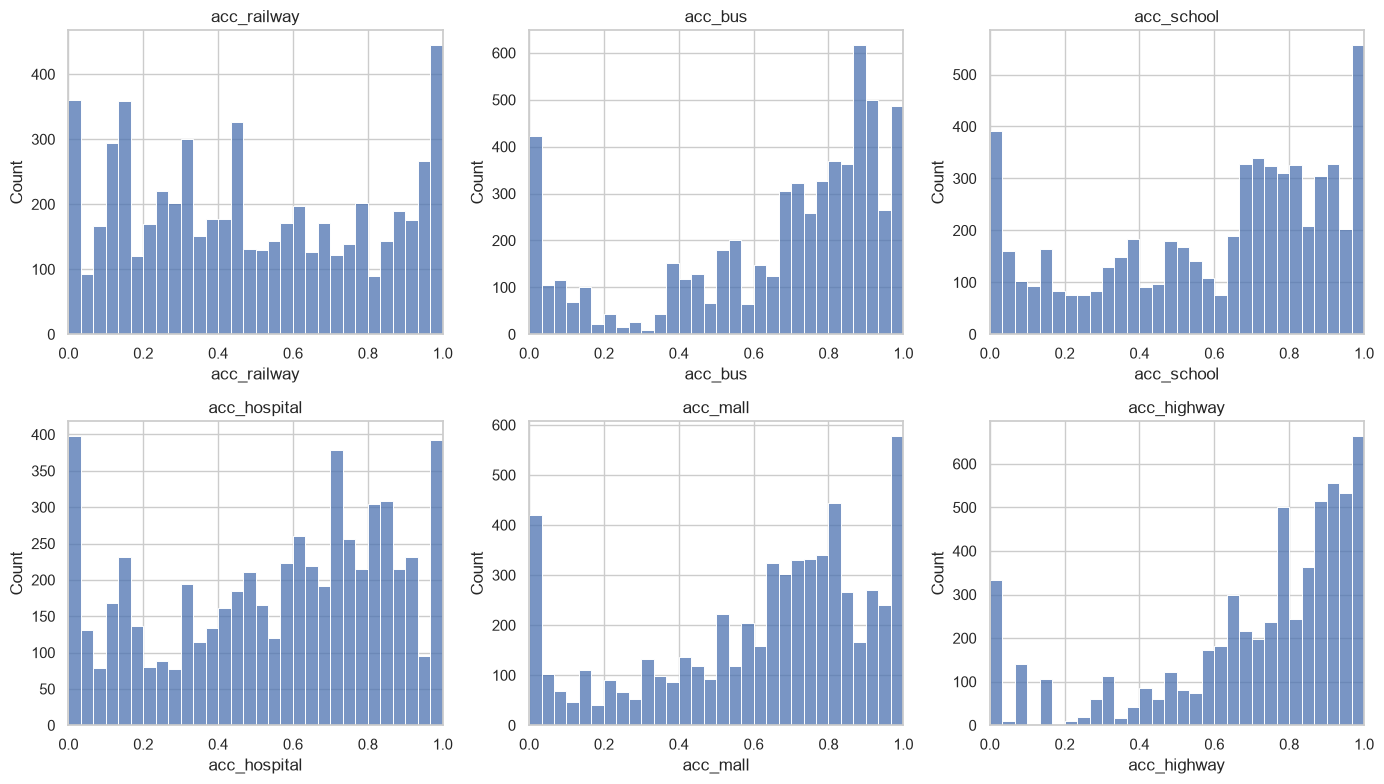

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for col, ax in zip(acc_train.columns, axes.flat):
    sns.histplot(acc_train[col], bins=30, ax=ax)
    ax.set_title(col)
    ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

In [40]:
WEIGHTS = {
    "railway": 0.20,
    "hospital": 0.20,
    "highway": 0.15,
    "school": 0.15,
    "mall": 0.15,
    "bus": 0.15
}

In [41]:
print("Sum of weights:", sum(WEIGHTS.values()))

Sum of weights: 1.0


In [42]:
def add_access_features(d, params, weights):
    comp = access_components(d, params)

    d = d.copy()

    # Equal-weight accessibility score
    d["access_plain"] = comp.mean(axis=1)

    # Keep only weights for components that actually exist
    available_weights = {
        f"acc_{k}": v
        for k, v in weights.items()
        if f"acc_{k}" in comp.columns
    }

    if not available_weights:
        raise ValueError(
            "No accessibility components match the supplied weights."
        )

    w = pd.Series(available_weights, dtype=float)

    if (w < 0).any() or w.sum() <= 0:
        raise ValueError(
            "Accessibility weights must be non-negative "
            "and have a positive sum."
        )

    # Normalize the selected weights to sum to 1
    w = w / w.sum()

    # Weighted accessibility score
    d["access_weighted"] = (
        comp[w.index] * w
    ).sum(axis=1, min_count=len(w))

    return d

In [43]:
full = add_access_features(
    full,
    access_params,
    WEIGHTS
)

print("Updated dataset shape:", full.shape)

print("\nAccessibility scores:")
display(
    full[
        [
            "access_plain",
            "access_weighted"
        ]
    ].head(10)
)

Updated dataset shape: (7457, 40)

Accessibility scores:


,access_plain,access_weighted
0,0.268284,0.262550
1,0.228658,0.219791
2,0.589504,0.583001
3,0.557270,0.553828
4,0.429749,0.408136
5,0.552357,0.544628
6,0.372137,0.373689
7,0.429749,0.408136
8,0.687221,0.664595
9,0.551639,0.570860


In [44]:
display(
    full[
        [
            "access_plain",
            "access_weighted"
        ]
    ]
    .describe()
    .T
    .round(3)
)

,count,mean,std,min,25%,50%,75%,max
access_plain,7457.0,0.604,0.222,0.052,0.438,0.656,0.780,0.971
access_weighted,7457.0,0.596,0.222,0.046,0.423,0.646,0.776,0.972


In [45]:
score_cols = [
    "access_plain",
    "access_weighted"
]

print("Missing scores:")
print(full[score_cols].isna().sum())

print("\nScores below 0:")
print((full[score_cols] < 0).sum())

print("\nScores above 1:")
print((full[score_cols] > 1).sum())

print("\nNumber of unique values:")
print(full[score_cols].nunique())

Missing scores:
access_plain       0
access_weighted    0
dtype: int64

Scores below 0:
access_plain       0
access_weighted    0
dtype: int64

Scores above 1:
access_plain       0
access_weighted    0
dtype: int64

Number of unique values:
access_plain       1137
access_weighted    1137
dtype: int64


In [46]:
tr = full.loc[train_idx].copy()

print("Training rows:", len(tr))
print("Test rows:", len(test_idx))

print("\nTraining dataset shape:", tr.shape)

Training rows: 5965
Test rows: 1492

Training dataset shape: (5965, 40)


In [47]:
tr["price_per_sqft"] = (
    tr["price_lakhs"] * 1e5
    / tr["area_sqft"]
)

print("Price per square foot statistics:")
display(
    tr["price_per_sqft"]
    .describe()
    .round(2)
)

Price per square foot statistics:


count     5965.00
mean     13128.00
std       6282.70
min       3395.06
25%       9074.07
50%      11609.07
75%      15000.00
max      57547.59
Name: price_per_sqft, dtype: float64

In [48]:
corr_cols = [
    "access_plain",
    "access_weighted",
    "price_per_sqft",
    "log_price"
]

corr = tr[corr_cols].corr(method="spearman")

display(corr.round(3))

,access_plain,access_weighted,price_per_sqft,log_price
access_plain,1.000,0.998,0.295,0.365
access_weighted,0.998,1.000,0.301,0.370
price_per_sqft,0.295,0.301,1.000,0.766
log_price,0.365,0.370,0.766,1.000


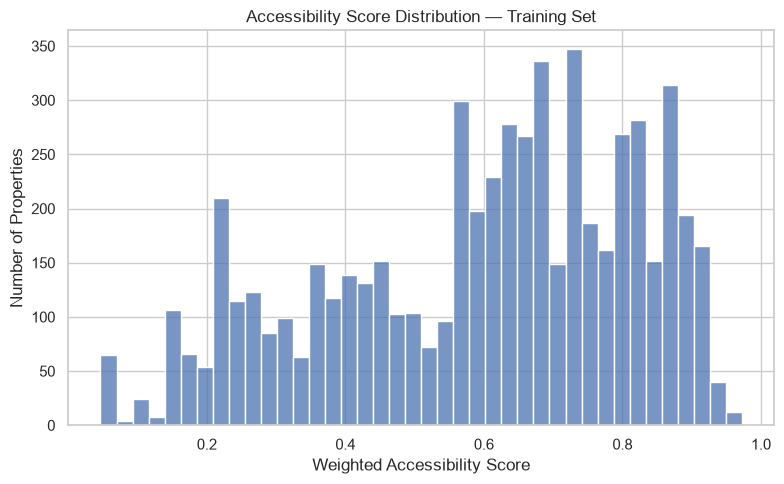

In [49]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    tr["access_weighted"],
    bins=40,
    ax=ax
)

ax.set_title("Accessibility Score Distribution — Training Set")
ax.set_xlabel("Weighted Accessibility Score")
ax.set_ylabel("Number of Properties")

plt.tight_layout()
plt.show()

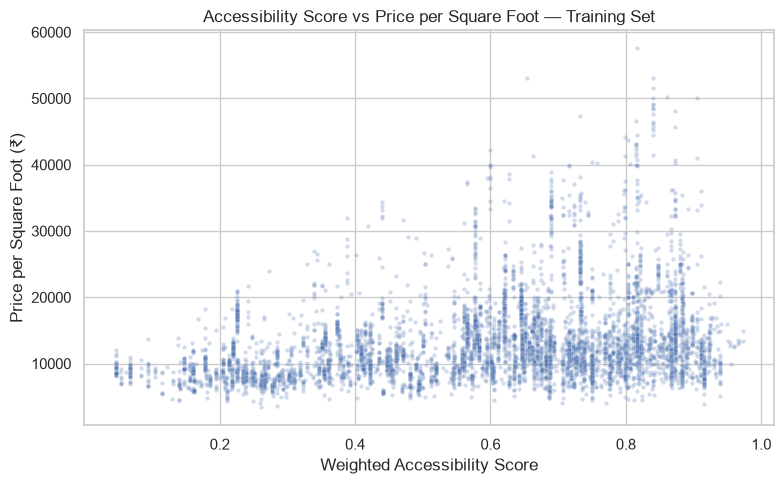

In [50]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    data=tr,
    x="access_weighted",
    y="price_per_sqft",
    alpha=0.25,
    s=10,
    ax=ax
)

ax.set_title(
    "Accessibility Score vs Price per Square Foot — Training Set"
)

ax.set_xlabel("Weighted Accessibility Score")
ax.set_ylabel("Price per Square Foot (₹)")

plt.tight_layout()
plt.show()

In [51]:
inspection_cols = [
    "prop_id",
    "latitude",
    "longitude",
    "dist_railway_km",
    "dist_bus_km",
    "dist_school_km",
    "dist_hospital_km",
    "dist_mall_km",
    "dist_highway_km",
    "access_plain",
    "access_weighted"
]

inspection_cols = [
    c for c in inspection_cols if c in full.columns
]

tr_sorted = tr.sort_values("access_weighted")

selected = pd.concat([
    tr_sorted.head(1),
    tr_sorted.iloc[[len(tr_sorted) // 2]],
    tr_sorted.tail(1)
])

display(
    selected[inspection_cols]
    .sort_values("access_weighted")
    .reset_index(drop=True)
)

,prop_id,latitude,longitude,dist_railway_km,dist_bus_km,dist_school_km,dist_hospital_km,dist_mall_km,dist_highway_km,access_plain,access_weighted
0,J71594938,28.356562,76.973291,9.973352,8.372775,2.657480,3.480516,6.011039,0.053727,0.051551,0.046396
1,P70727474,28.409433,77.105276,1.543245,1.061857,1.271976,1.212183,1.784675,0.004376,0.649092,0.645555
2,I71614008,28.477884,77.084474,0.485388,0.374484,0.156227,0.116224,0.158158,0.000510,0.970910,0.972499


In [52]:
print("PART C: ACCESSIBILITY FEATURE ENGINEERING")
print("=" * 55)

print("\nSelected accessibility columns:")
print(ACC_COLS)

print("\nNormalization parameters:")
for col, params in access_params.items():
    print(
        f"{col}: "
        f"lo={params['lo']:.4f}, "
        f"hi={params['hi']:.4f}"
    )

print("\nAccessibility component columns:")
display(
    access_components(
        full.loc[train_idx],
        access_params
    ).head()
)

print("\nAccessibility score statistics:")
display(
    full.loc[
        train_idx,
        ["access_plain", "access_weighted"]
    ]
    .describe()
    .T
    .round(3)
)

print("\nMissing accessibility scores:")
print(
    full.loc[
        train_idx,
        ["access_plain", "access_weighted"]
    ]
    .isna()
    .sum()
)

print("\nScores outside [0, 1]:")
print(
    (
        (full[["access_plain", "access_weighted"]] < 0)
        | (full[["access_plain", "access_weighted"]] > 1)
    ).sum()
)

PART C: ACCESSIBILITY FEATURE ENGINEERING

Selected accessibility columns:
['dist_railway_km', 'dist_bus_km', 'dist_school_km', 'dist_hospital_km', 'dist_mall_km', 'dist_highway_km']

Normalization parameters:
dist_railway_km: lo=0.3476, hi=2.1675
dist_bus_km: lo=0.1653, hi=2.1796
dist_school_km: lo=0.0370, hi=1.5327
dist_hospital_km: lo=0.2161, hi=1.4985
dist_mall_km: lo=0.1782, hi=1.9475
dist_highway_km: lo=0.0011, hi=0.0615

Accessibility component columns:


,acc_railway,acc_bus,acc_school,acc_hospital,acc_mall,acc_highway
434,0.628111,0.803053,0.183413,0.109965,0.821121,0.928291
751,0.346533,0.000000,0.493176,0.000000,0.000000,0.701380
2692,0.089163,1.000000,0.729301,0.650150,0.760040,0.837040
4763,0.137667,0.135975,0.000000,0.460345,0.230286,0.403173
4039,0.672632,0.709066,0.426311,0.484631,0.500244,0.956901



Accessibility score statistics:


,count,mean,std,min,25%,50%,75%,max
access_plain,5965.0,0.604,0.222,0.052,0.438,0.656,0.780,0.971
access_weighted,5965.0,0.596,0.222,0.046,0.423,0.646,0.777,0.972



Missing accessibility scores:
access_plain       0
access_weighted    0
dtype: int64

Scores outside [0, 1]:
access_plain       0
access_weighted    0
dtype: int64


In [53]:
import numpy as np
import pandas as pd

In [54]:
# Amenity types to include in the density index
COUNT_BASES = ["school", "hospital", "bus", "mall"]

# Expected count columns
expected_count_cols = [
    f"n_{base}_{radius}"
    for base in COUNT_BASES
    for radius in ["1km", "2km"]
]

# Show which columns exist
available_count_cols = [
    col for col in expected_count_cols
    if col in df.columns
]

missing_count_cols = [
    col for col in expected_count_cols
    if col not in df.columns
]

print("Available amenity-count columns:")
print(available_count_cols)

print("\nMissing amenity-count columns:")
print(missing_count_cols)

Available amenity-count columns:
['n_school_1km', 'n_school_2km', 'n_hospital_1km', 'n_hospital_2km', 'n_bus_1km', 'n_bus_2km', 'n_mall_1km', 'n_mall_2km']

Missing amenity-count columns:
[]


In [55]:
print("Missing values:")
display(df[available_count_cols].isna().sum())

print("\nNegative counts:")
display((df[available_count_cols] < 0).sum())

print("\nNumber of unique values:")
display(df[available_count_cols].nunique())

print("\nSummary statistics:")
display(df[available_count_cols].describe().T.round(2))

Missing values:


n_school_1km      0
n_school_2km      0
n_hospital_1km    0
n_hospital_2km    0
n_bus_1km         0
n_bus_2km         0
n_mall_1km        0
n_mall_2km        0
dtype: int64


Negative counts:


n_school_1km      0
n_school_2km      0
n_hospital_1km    0
n_hospital_2km    0
n_bus_1km         0
n_bus_2km         0
n_mall_1km        0
n_mall_2km        0
dtype: int64


Number of unique values:


n_school_1km      17
n_school_2km      37
n_hospital_1km    12
n_hospital_2km    32
n_bus_1km         19
n_bus_2km         41
n_mall_1km        14
n_mall_2km        23
dtype: int64


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
n_school_1km,7457.0,2.52,3.32,0.0,0.0,1.0,4.0,16.0
n_school_2km,7457.0,9.14,8.85,0.0,1.0,7.0,15.0,36.0
n_hospital_1km,7457.0,1.37,1.99,0.0,0.0,0.0,2.0,25.0
n_hospital_2km,7457.0,5.48,5.29,0.0,0.0,5.0,9.0,45.0
n_bus_1km,7457.0,2.60,3.51,0.0,0.0,1.0,4.0,19.0
n_bus_2km,7457.0,10.26,10.16,0.0,0.0,8.0,18.0,40.0
n_mall_1km,7457.0,1.40,2.53,0.0,0.0,0.0,1.0,13.0
n_mall_2km,7457.0,5.03,5.85,0.0,0.0,2.0,8.0,22.0


In [56]:
COUNT_BASES = ["school", "hospital", "bus", "mall"]

def fit_density_params(train, count_bases):
    params = {}

    for base in count_bases:
        for radius in ["1km", "2km"]:
            col = f"n_{base}_{radius}"

            if col not in train.columns:
                continue

            params[col] = max(
                float(train[col].quantile(0.95)),
                1.0
            )

    return params


density_params = fit_density_params(
    df.loc[train_idx],
    COUNT_BASES
)

print("Density normalization parameters:")

for col, value in density_params.items():
    print(f"{col}: {value:.2f}")

Density normalization parameters:
n_school_1km: 10.00
n_school_2km: 27.00
n_hospital_1km: 5.00
n_hospital_2km: 14.00
n_bus_1km: 10.00
n_bus_2km: 28.00
n_mall_1km: 8.00
n_mall_2km: 17.00


In [57]:
def add_density_features(d, params, count_bases):
    d = d.copy()

    for radius in ["1km", "2km"]:

        # Select available amenity-count columns
        cols = [
            f"n_{base}_{radius}"
            for base in count_bases
            if f"n_{base}_{radius}" in params
        ]

        if not cols:
            raise ValueError(
                f"No amenity-count columns available for {radius}"
            )

        # Normalize each amenity count separately
        normalized_counts = pd.DataFrame(
            {
                col: (d[col] / params[col]).clip(0, 1)
                for col in cols
            },
            index=d.index
        )

        # Average normalized counts
        d[f"amenity_density_{radius}"] = (
            normalized_counts.mean(axis=1)
        )

        # Sum original, unnormalized counts
        d[f"n_total_{radius}"] = d[cols].sum(axis=1)

    return d

In [58]:
full = add_density_features(
    full,
    density_params,
    COUNT_BASES
)

density_features = [
    "amenity_density_1km",
    "amenity_density_2km",
    "n_total_1km",
    "n_total_2km"
]

display(
    full[density_features].describe().T.round(3)
)

,count,mean,std,min,25%,50%,75%,max
amenity_density_1km,7457.0,0.228,0.248,0.0,0.00,0.138,0.400,1.000
amenity_density_2km,7457.0,0.339,0.297,0.0,0.05,0.290,0.602,0.937
n_total_1km,7457.0,7.887,8.863,0.0,0.00,5.000,13.000,39.000
n_total_2km,7457.0,29.914,26.648,0.0,3.00,24.000,52.000,90.000


In [59]:
density_features = [
    "amenity_density_1km",
    "amenity_density_2km",
    "n_total_1km",
    "n_total_2km"
]

print("Missing values:")
display(full[density_features].isna().sum())

density_cols = [
    "amenity_density_1km",
    "amenity_density_2km"
]

print("\nDensity values below 0:")
display((full[density_cols] < 0).sum())

print("\nDensity values above 1:")
display((full[density_cols] > 1).sum())

print("\nNegative raw totals:")
display((full[["n_total_1km", "n_total_2km"]] < 0).sum())

print("\nProperties where 2 km total < 1 km total:")
print(
    (full["n_total_2km"] < full["n_total_1km"]).sum()
)

Missing values:


amenity_density_1km    0
amenity_density_2km    0
n_total_1km            0
n_total_2km            0
dtype: int64


Density values below 0:


amenity_density_1km    0
amenity_density_2km    0
dtype: int64


Density values above 1:


amenity_density_1km    0
amenity_density_2km    0
dtype: int64


Negative raw totals:


n_total_1km    0
n_total_2km    0
dtype: int64


Properties where 2 km total < 1 km total:
0


In [60]:
density_correlation_cols = [
    "amenity_density_1km",
    "amenity_density_2km",
    "n_total_1km",
    "n_total_2km"
]

print("Pearson correlation:")
display(
    full[density_correlation_cols]
    .corr(method="pearson")
    .round(3)
)

print("\nSpearman correlation:")
display(
    full[density_correlation_cols]
    .corr(method="spearman")
    .round(3)
)

Pearson correlation:


,amenity_density_1km,amenity_density_2km,n_total_1km,n_total_2km
amenity_density_1km,1.000,0.886,0.987,0.879
amenity_density_2km,0.886,1.000,0.872,0.994
n_total_1km,0.987,0.872,1.000,0.872
n_total_2km,0.879,0.994,0.872,1.000



Spearman correlation:


,amenity_density_1km,amenity_density_2km,n_total_1km,n_total_2km
amenity_density_1km,1.000,0.911,0.996,0.907
amenity_density_2km,0.911,1.000,0.912,0.996
n_total_1km,0.996,0.912,1.000,0.911
n_total_2km,0.907,0.996,0.911,1.000


In [61]:
print("Available accessibility scores:")

for col in ["access_weighted", "access_plain"]:
    print(f"{col}: {col in full.columns}")

Available accessibility scores:
access_weighted: True
access_plain: True


In [62]:
SCORE = "access_weighted"

In [63]:
print("Selected score:", SCORE)

display(
    full[[SCORE]]
    .describe()
    .T
    .round(3)
)

print("\nMissing values:", full[SCORE].isna().sum())

Selected score: access_weighted


,count,mean,std,min,25%,50%,75%,max
access_weighted,7457.0,0.596,0.222,0.046,0.423,0.646,0.776,0.972



Missing values: 0


In [64]:
def fit_bin_edges(train, score):
    return [
        float(train[score].quantile(1 / 3)),
        float(train[score].quantile(2 / 3))
    ]


edges = fit_bin_edges(
    full.loc[train_idx],
    SCORE
)

print("Accessibility score:", SCORE)
print("Remote/Mid boundary:", edges[0])
print("Mid/Prime boundary:", edges[1])

Accessibility score: access_weighted
Remote/Mid boundary: 0.5304844319140228
Mid/Prime boundary: 0.7306834676784597


In [65]:
def add_access_class(d, edges, score):
    d = d.copy()

    d["access_class"] = pd.cut(
        d[score],
        bins=[-np.inf, edges[0], edges[1], np.inf],
        labels=["Remote", "Mid", "Prime"]
    ).astype("string")

    return d

In [66]:
full = add_access_class(
    full,
    edges,
    SCORE
)

print("Category counts:")
display(full["access_class"].value_counts())

print("\nCategory proportions:")
display(
    full["access_class"]
    .value_counts(normalize=True)
    .sort_index()
    .round(3)
)

Category counts:


access_class
Mid       2507
Prime     2480
Remote    2470
Name: count, dtype: int64[pyarrow]


Category proportions:


access_class
Mid       0.336
Prime     0.333
Remote    0.331
Name: proportion, dtype: double[pyarrow]

In [67]:
print("Missing category labels:")
print(full["access_class"].isna().sum())

print("\nScore ranges by category:")

display(
    full.groupby("access_class", observed=True)[SCORE]
    .agg(["min", "median", "max", "count"])
    .round(3)
)

Missing category labels:
0

Score ranges by category:


,min,median,max,count
access_class,,,,
Mid,0.534,0.646,0.731,2507
Prime,0.731,0.819,0.972,2480
Remote,0.046,0.339,0.530,2470


In [68]:
tr = full.loc[train_idx].copy()

tr["price_per_sqft"] = (
    tr["price_lakhs"] * 1e5 / tr["area_sqft"]
)

print("Training rows:", len(tr))

Training rows: 5965


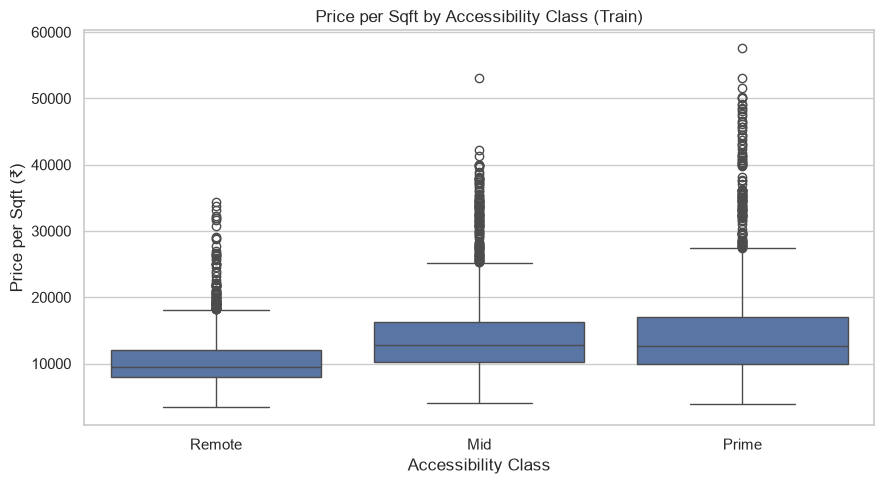

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

order = ["Remote", "Mid", "Prime"]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=tr,
    x="access_class",
    y="price_per_sqft",
    order=order
)

plt.title("Price per Sqft by Accessibility Class (Train)")
plt.xlabel("Accessibility Class")
plt.ylabel("Price per Sqft (₹)")

plt.tight_layout()

plt.savefig(
    "../reports/figures/09_access_class_price.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [70]:
median_price_by_access = (
    tr.groupby("access_class", observed=True)["price_per_sqft"]
    .median()
    .reindex(order)
)

print("Median price per sqft by accessibility class:")
display(median_price_by_access.round(0))

Median price per sqft by accessibility class:


access_class
Remote     9533.0
Mid       12768.0
Prime     12679.0
Name: price_per_sqft, dtype: float64

In [71]:
print("Training properties per category:")

display(
    tr["access_class"]
    .value_counts()
    .reindex(order)
)

Training properties per category:


access_class
Remote    1989
Mid       1989
Prime     1987
Name: count, dtype: int64[pyarrow]

In [72]:
output_path = "../data/processed/feature_engineered_v1.csv"

full.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Dataset shape:", full.shape)
print("\nNew feature:")
print("access_class")

Saved: ../data/processed/feature_engineered_v1.csv
Dataset shape: (7457, 45)

New feature:
access_class


In [73]:
print("Available accessibility scores:")

for col in ["access_weighted", "access_plain"]:
    print(f"{col}: {col in full.columns}")

Available accessibility scores:
access_weighted: True
access_plain: True


In [74]:
SCORE = "access_weighted"

print("Selected score:", SCORE)

display(full[[SCORE]].describe().T.round(3))

print("\nMissing values:", full[SCORE].isna().sum())

Selected score: access_weighted


,count,mean,std,min,25%,50%,75%,max
access_weighted,7457.0,0.596,0.222,0.046,0.423,0.646,0.776,0.972



Missing values: 0


In [75]:
def fit_bin_edges(train, score):
    return [
        float(train[score].quantile(1/3)),
        float(train[score].quantile(2/3))
    ]

edges = fit_bin_edges(full.loc[train_idx], SCORE)

print("Accessibility score:", SCORE)
print("Remote/Mid boundary:", round(edges[0], 4))
print("Mid/Prime boundary:", round(edges[1], 4))

Accessibility score: access_weighted
Remote/Mid boundary: 0.5305
Mid/Prime boundary: 0.7307


In [76]:
def add_access_class(d, edges, score):
    d = d.copy()

    d["access_class"] = pd.cut(
        d[score],
        bins=[-np.inf, edges[0], edges[1], np.inf],
        labels=["Remote", "Mid", "Prime"]
    ).astype("string")

    return d


full = add_access_class(full, edges, SCORE)

print("Category counts:")
display(full["access_class"].value_counts())

print("\nCategory proportions:")
display(
    full["access_class"]
    .value_counts(normalize=True)
    .sort_index()
    .round(3)
)

Category counts:


access_class
Mid       2507
Prime     2480
Remote    2470
Name: count, dtype: int64[pyarrow]


Category proportions:


access_class
Mid       0.336
Prime     0.333
Remote    0.331
Name: proportion, dtype: double[pyarrow]

In [77]:
print("Missing category labels:")
print(full["access_class"].isna().sum())

print("\nScore ranges by category:")
display(
    full.groupby("access_class", observed=True)[SCORE]
    .agg(["min", "median", "max", "count"])
    .round(3)
)

Missing category labels:
0

Score ranges by category:


,min,median,max,count
access_class,,,,
Mid,0.534,0.646,0.731,2507
Prime,0.731,0.819,0.972,2480
Remote,0.046,0.339,0.530,2470


In [78]:
tr = full.loc[train_idx].copy()

tr["price_per_sqft"] = (
    tr["price_lakhs"] * 1e5 / tr["area_sqft"]
)

print("Training rows:", len(tr))
print("Missing price per sqft:", tr["price_per_sqft"].isna().sum())

display(
    tr.groupby("access_class", observed=True)["price_per_sqft"]
    .agg(["count", "median", "mean"])
    .reindex(["Remote", "Mid", "Prime"])
    .round(2)
)

Training rows: 5965
Missing price per sqft: 0


,count,median,mean
access_class,,,
Remote,1989,9532.71,10511.00
Mid,1989,12767.64,14112.27
Prime,1987,12678.65,14762.37


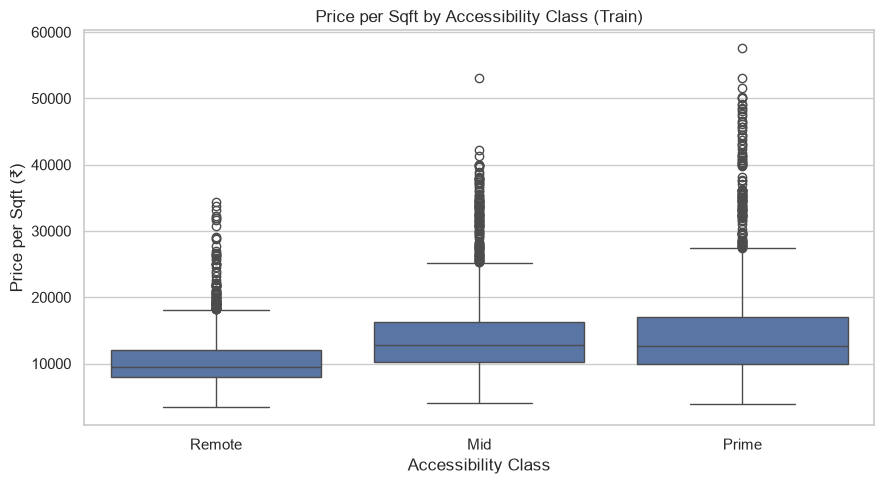

Saved: reports/figures/09_access_class_price.png


In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

order = ["Remote", "Mid", "Prime"]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=tr,
    x="access_class",
    y="price_per_sqft",
    order=order
)

plt.title("Price per Sqft by Accessibility Class (Train)")
plt.xlabel("Accessibility Class")
plt.ylabel("Price per Sqft (₹)")
plt.tight_layout()

plt.savefig(
    "../reports/figures/09_access_class_price.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved: reports/figures/09_access_class_price.png")

In [80]:
print("Dataset shape:", full.shape)

print("\nTraining index count:", len(train_idx))
print("Test index count:", len(test_idx))

print("\nTarget column exists:", "log_price" in full.columns)

print("\nBasic numeric features:")
print("BASE_NUM exists:", "BASE_NUM" in globals())

print("\nGeographic features:")
print("GEO exists:", "GEO" in globals())

print("\nAmenity numeric features:")
print("AMEN_NUM exists:", "AMEN_NUM" in globals())

print("\nBase categorical features:")
print("BASE_CAT exists:", "BASE_CAT" in globals())

print("\nAmenity categorical features:")
print("AMEN_CAT exists:", "AMEN_CAT" in globals())

Dataset shape: (7457, 45)

Training index count: 5965
Test index count: 1492

Target column exists: True

Basic numeric features:
BASE_NUM exists: False

Geographic features:
GEO exists: False

Amenity numeric features:
AMEN_NUM exists: False

Base categorical features:
BASE_CAT exists: False

Amenity categorical features:
AMEN_CAT exists: False


In [81]:
train = full.loc[train_idx].copy()

print("Training shape:", train.shape)
print("Target available:", "log_price" in train.columns)

Training shape: (5965, 45)
Target available: True


In [82]:
print("Total columns:", len(full.columns))

for i, col in enumerate(full.columns, start=1):
    print(f"{i:2}. {col}")

Total columns: 45
 1. prop_id
 2. latitude
 3. longitude
 4. property_type
 5. owntype
 6. bedroom_num
 7. bathroom_num
 8. balcony_num
 9. furnish
10. facing
11. age
12. floor_num
13. total_floor
14. total_landmark_count
15. area_sqft
16. area_is_carpet
17. locality_grouped
18. price_lakhs
19. log_price
20. dist_railway_km
21. dist_bus_km
22. dist_school_km
23. dist_hospital_km
24. dist_mall_km
25. dist_highway_km
26. dist_mainroad_km
27. n_school_1km
28. n_school_2km
29. n_hospital_1km
30. n_hospital_2km
31. n_bus_1km
32. n_bus_2km
33. n_mall_1km
34. n_mall_2km
35. bed_bath_ratio
36. total_rooms
37. area_per_bedroom
38. floor_ratio
39. access_plain
40. access_weighted
41. amenity_density_1km
42. n_total_1km
43. amenity_density_2km
44. n_total_2km
45. access_class


In [83]:
# ==========================================
# G1: Define feature groups
# ==========================================

# 1. Base numeric features
BASE_NUM = [
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "floor_num",
    "total_floor",
    "total_landmark_count",
    "area_sqft",
]

# 2. Geographic coordinates
GEO = [
    "latitude",
    "longitude",
]

# 3. Amenity and accessibility numeric features
AMEN_NUM = [
    "dist_railway_km",
    "dist_bus_km",
    "dist_school_km",
    "dist_hospital_km",
    "dist_mall_km",
    "dist_highway_km",
    "dist_mainroad_km",

    "acc_railway",
    "acc_bus",
    "acc_school",
    "acc_hospital",
    "acc_mall",
    "acc_highway",
    "access_plain",
    "access_weighted",

    "n_school_1km",
    "n_school_2km",
    "n_hospital_1km",
    "n_hospital_2km",
    "n_bus_1km",
    "n_bus_2km",
    "n_mall_1km",
    "n_mall_2km",

    "amenity_density_1km",
    "amenity_density_2km",
    "n_total_1km",
    "n_total_2km",
]

# 4. Base categorical features
BASE_CAT = [
    "property_type",
    "owntype",
    "furnish",
    "facing",
    "age",
    "locality_grouped",
]

# 5. Additional categorical accessibility feature
AMEN_CAT = [
    "access_class",
]

# Check whether all specified columns exist
groups = {
    "BASE_NUM": BASE_NUM,
    "GEO": GEO,
    "AMEN_NUM": AMEN_NUM,
    "BASE_CAT": BASE_CAT,
    "AMEN_CAT": AMEN_CAT,
}

for group_name, columns in groups.items():
    missing = [col for col in columns if col not in full.columns]
    print(f"{group_name}: {len(columns)} features")
    if missing:
        print("  Missing columns:", missing)

print("\nFeature groups defined.")

BASE_NUM: 7 features
GEO: 2 features
AMEN_NUM: 27 features
  Missing columns: ['acc_railway', 'acc_bus', 'acc_school', 'acc_hospital', 'acc_mall', 'acc_highway']
BASE_CAT: 6 features
AMEN_CAT: 1 features

Feature groups defined.


In [84]:
# Remove accessibility component columns that do not exist
AMEN_NUM = [
    col for col in AMEN_NUM
    if col in full.columns
]

print("Updated AMEN_NUM:", len(AMEN_NUM))
print(AMEN_NUM)

# Verify every feature group
for name, columns in groups.items():
    missing = [col for col in columns if col not in full.columns]
    print(f"{name}: {len([c for c in columns if c in full.columns])} valid features"
          + (f" | Missing: {missing}" if missing else ""))

Updated AMEN_NUM: 21
['dist_railway_km', 'dist_bus_km', 'dist_school_km', 'dist_hospital_km', 'dist_mall_km', 'dist_highway_km', 'dist_mainroad_km', 'access_plain', 'access_weighted', 'n_school_1km', 'n_school_2km', 'n_hospital_1km', 'n_hospital_2km', 'n_bus_1km', 'n_bus_2km', 'n_mall_1km', 'n_mall_2km', 'amenity_density_1km', 'amenity_density_2km', 'n_total_1km', 'n_total_2km']
BASE_NUM: 7 valid features
GEO: 2 valid features
AMEN_NUM: 21 valid features | Missing: ['acc_railway', 'acc_bus', 'acc_school', 'acc_hospital', 'acc_mall', 'acc_highway']
BASE_CAT: 6 valid features
AMEN_CAT: 1 valid features


In [85]:
import pandas as pd
import numpy as np

# Training data only
train = full.loc[train_idx].copy()

# Candidate numeric features
num_candidates = BASE_NUM + GEO + AMEN_NUM

# Keep existing columns and remove duplicates
num_candidates = list(dict.fromkeys(
    col for col in num_candidates
    if col in train.columns
))

# Correlation matrix
corr_matrix = train[num_candidates].corr(method="pearson")

# Extract highly correlated pairs
high_corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        col1 = corr_matrix.columns[i]
        col2 = corr_matrix.columns[j]
        corr_value = corr_matrix.iloc[i, j]

        if pd.notna(corr_value) and abs(corr_value) > 0.90:
            high_corr_pairs.append({
                "Feature 1": col1,
                "Feature 2": col2,
                "Correlation": round(corr_value, 3)
            })

high_corr_df = pd.DataFrame(high_corr_pairs)

if high_corr_df.empty:
    print("No feature pairs have absolute correlation greater than 0.90.")
else:
    high_corr_df["Absolute correlation"] = high_corr_df["Correlation"].abs()
    high_corr_df = high_corr_df.sort_values(
        "Absolute correlation", ascending=False
    ).drop(columns="Absolute correlation")

    display(high_corr_df.reset_index(drop=True))

,Feature 1,Feature 2,Correlation
0,dist_highway_km,dist_mainroad_km,1.000
1,access_plain,access_weighted,0.998
2,amenity_density_2km,n_total_2km,0.994
3,amenity_density_1km,n_total_1km,0.987
4,dist_bus_km,dist_mall_km,0.926
5,n_school_2km,n_total_2km,0.917
6,n_school_2km,amenity_density_2km,0.909
7,n_bus_2km,n_total_2km,0.907


In [86]:
# Check whether highway and main-road distances are identical

distance_diff = (
    train["dist_highway_km"] - train["dist_mainroad_km"]
).abs()

print("Maximum absolute difference:",
      distance_diff.max())

print("Number of rows with different values:",
      (distance_diff > 1e-9).sum())

print("\nSummary of absolute differences:")
display(distance_diff.describe())

Maximum absolute difference: 0.013193233263990498
Number of rows with different values: 5

Summary of absolute differences:


count    5965.000000
mean        0.000005
std         0.000238
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         0.013193
dtype: float64

In [87]:
# ==========================================
# G1.5: Initial correlation-based pruning
# ==========================================

# Features to remove from the initial numeric candidate set
drop_corr = [
    "dist_mainroad_km",       # Nearly identical to dist_highway_km
    "access_plain",           # Highly correlated with access_weighted
    "n_total_1km",             # Highly correlated with amenity_density_1km
    "n_total_2km",             # Highly correlated with amenity_density_2km
]

# Keep the remaining numeric features
kept_num = [
    col for col in num_candidates
    if col not in drop_corr
]

print("Numeric features before pruning:", len(num_candidates))
print("Numeric features removed:", len(drop_corr))
print("Numeric features after pruning:", len(kept_num))

print("\nRemoved features:")
for col in drop_corr:
    print("-", col)

print("\nRemaining numeric features:")
for col in kept_num:
    print("-", col)

Numeric features before pruning: 30
Numeric features removed: 4
Numeric features after pruning: 26

Removed features:
- dist_mainroad_km
- access_plain
- n_total_1km
- n_total_2km

Remaining numeric features:
- bedroom_num
- bathroom_num
- balcony_num
- floor_num
- total_floor
- total_landmark_count
- area_sqft
- latitude
- longitude
- dist_railway_km
- dist_bus_km
- dist_school_km
- dist_hospital_km
- dist_mall_km
- dist_highway_km
- access_weighted
- n_school_1km
- n_school_2km
- n_hospital_1km
- n_hospital_2km
- n_bus_1km
- n_bus_2km
- n_mall_1km
- n_mall_2km
- amenity_density_1km
- amenity_density_2km


In [88]:
# ==========================================
# G2.1: Prepare data for permutation importance
# ==========================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score

# Categorical feature groups
cat_all = BASE_CAT + AMEN_CAT

# Keep only columns that exist in the dataset
cat_all = list(dict.fromkeys(
    col for col in cat_all
    if col in full.columns
))

# Training data only
train = full.loc[train_idx].copy()

# Features and target
feature_cols = kept_num + cat_all

X = train[feature_cols].copy()
y = train["log_price"].copy()

# Treat categorical columns as strings
for col in cat_all:
    X[col] = X[col].astype("string")

# Split training data into model-training and validation subsets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training subset:", X_train.shape)
print("Validation subset:", X_val.shape)
print("Numeric features:", len(kept_num))
print("Categorical features:", len(cat_all))
print("Target:", "log_price")

Training subset: (4772, 33)
Validation subset: (1193, 33)
Numeric features: 26
Categorical features: 7
Target: log_price


In [89]:
# ==========================================
# G2.2: Train Random Forest pipeline
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Preprocessing for numeric features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, kept_num),
        ("cat", categorical_transformer, cat_all)
    ],
    remainder="drop"
)

# Random Forest model
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

# Train
rf_pipeline.fit(X_train, y_train)

# Validate
val_predictions = rf_pipeline.predict(X_val)

print("Validation R²:", round(r2_score(y_val, val_predictions), 4))
print("Validation MAE (log scale):",
      round(mean_absolute_error(y_val, val_predictions), 4))
print("Validation RMSE (log scale):",
      round(np.sqrt(mean_squared_error(y_val, val_predictions)), 4))

Validation R²: 0.9064
Validation MAE (log scale): 0.1277
Validation RMSE (log scale): 0.1874


In [90]:
# ==========================================
# G2.3: Permutation importance
# ==========================================

perm_result = permutation_importance(
    rf_pipeline,
    X_val,
    y_val,
    n_repeats=5,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_mean": perm_result.importances_mean,
    "Importance_std": perm_result.importances_std
})

importance_df = importance_df.sort_values(
    "Importance_mean",
    ascending=False
).reset_index(drop=True)

display(importance_df)

,Feature,Importance_mean,Importance_std
0,area_sqft,0.741696,0.018011
1,longitude,0.178093,0.006350
2,property_type,0.128095,0.008591
3,total_floor,0.080331,0.005723
4,bedroom_num,0.021798,0.000952
5,bathroom_num,0.019768,0.001965
6,latitude,0.014702,0.000937
7,locality_grouped,0.014692,0.000954
8,dist_railway_km,0.009386,0.000615
9,total_landmark_count,0.008136,0.000439


In [91]:
# ==========================================
# G2.5: Compare feature importance with noise
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score

# Copy data and add a random noise feature
X_noise = X.copy()

rng = np.random.default_rng(42)
X_noise["noise"] = rng.normal(size=len(X_noise))

# Split the same rows into training and validation sets
Xn_train, Xn_val, yn_train, yn_val = train_test_split(
    X_noise,
    y,
    test_size=0.20,
    random_state=42
)

# Build preprocessing for the new feature set
numeric_noise = kept_num + ["noise"]

preprocessor_noise = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_noise
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            cat_all
        )
    ]
)

rf_noise = Pipeline([
    ("preprocessor", preprocessor_noise),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

# Train and evaluate
rf_noise.fit(Xn_train, yn_train)

noise_predictions = rf_noise.predict(Xn_val)

print(
    "Validation R² with noise:",
    round(r2_score(yn_val, noise_predictions), 4)
)

# Calculate permutation importance
noise_result = permutation_importance(
    rf_noise,
    Xn_val,
    yn_val,
    n_repeats=5,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

noise_importance_df = pd.DataFrame({
    "Feature": Xn_val.columns,
    "Importance_mean": noise_result.importances_mean,
    "Importance_std": noise_result.importances_std
}).sort_values("Importance_mean", ascending=False).reset_index(drop=True)

display(noise_importance_df)

Validation R² with noise: 0.9047


,Feature,Importance_mean,Importance_std
0,area_sqft,0.743041,0.017362
1,longitude,0.177672,0.005976
2,property_type,0.129053,0.008585
3,total_floor,0.080436,0.005666
4,bedroom_num,0.022235,0.000986
5,bathroom_num,0.019293,0.002015
6,locality_grouped,0.014886,0.001071
7,latitude,0.014746,0.001104
8,dist_railway_km,0.009337,0.000669
9,total_landmark_count,0.007975,0.000390


In [92]:
# ==========================================
# G3.1: Define ablation feature groups
# ==========================================

# Base property features
BASE_FEATURES = BASE_NUM + BASE_CAT

# Base + geographic coordinates
BASE_GEO_FEATURES = BASE_FEATURES + GEO

# Base + geography + amenity features
FULL_FEATURES = BASE_GEO_FEATURES + AMEN_NUM + AMEN_CAT

# Remove duplicates and keep only existing columns
BASE_FEATURES = list(dict.fromkeys(
    c for c in BASE_FEATURES if c in full.columns
))

BASE_GEO_FEATURES = list(dict.fromkeys(
    c for c in BASE_GEO_FEATURES if c in full.columns
))

FULL_FEATURES = list(dict.fromkeys(
    c for c in FULL_FEATURES if c in full.columns
))

# Safety check: no target or target-derived fields in inputs
forbidden = {
    "price_lakhs",
    "log_price",
    "price_per_sqft",
    "prop_id"
}

for name, cols in {
    "BASE_FEATURES": BASE_FEATURES,
    "BASE_GEO_FEATURES": BASE_GEO_FEATURES,
    "FULL_FEATURES": FULL_FEATURES
}.items():
    leaked = forbidden.intersection(cols)
    print(f"{name}: {len(cols)} features")
    if leaked:
        print("WARNING — forbidden columns found:", leaked)

print("\nAdditional geographic features:", GEO)
print("Additional amenity features:", len(FULL_FEATURES) - len(BASE_GEO_FEATURES))

BASE_FEATURES: 13 features
BASE_GEO_FEATURES: 15 features
FULL_FEATURES: 37 features

Additional geographic features: ['latitude', 'longitude']
Additional amenity features: 22


In [93]:
# ==========================================
# G3.2: Reusable ablation evaluation function
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
import pandas as pd
import numpy as np

# Recreate the training data and fixed validation split
train = full.loc[train_idx].copy()

X_all = train.drop(columns=["price_lakhs", "log_price"], errors="ignore")
y_all = train["log_price"]

# Same split across all experiments
train_rows, val_rows = train_test_split(
    train.index,
    test_size=0.20,
    random_state=42
)

y_train_ablation = full.loc[train_rows, "log_price"]
y_val_ablation = full.loc[val_rows, "log_price"]


def evaluate_feature_group(feature_cols, group_name):
    """Train and evaluate a Random Forest on a selected feature group."""

    numeric_cols = [
        c for c in feature_cols
        if c in (BASE_NUM + GEO + AMEN_NUM)
    ]

    categorical_cols = [
        c for c in feature_cols
        if c in (BASE_CAT + AMEN_CAT)
    ]

    X_train_group = full.loc[train_rows, feature_cols].copy()
    X_val_group = full.loc[val_rows, feature_cols].copy()

    # Explicitly treat categorical codes as categories
    for col in categorical_cols:
        X_train_group[col] = X_train_group[col].astype("string")
        X_val_group[col] = X_val_group[col].astype("string")

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="median"))
                ]),
                numeric_cols
            ),
            (
                "cat",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))
                ]),
                categorical_cols
            )
        ],
        remainder="drop"
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1,
            min_samples_leaf=2
        ))
    ])

    model.fit(X_train_group, y_train_ablation)
    predictions = model.predict(X_val_group)

    return {
        "Experiment": group_name,
        "Feature_count": len(feature_cols),
        "Validation_R2": r2_score(y_val_ablation, predictions),
        "Validation_MAE_log": mean_absolute_error(
            y_val_ablation, predictions
        )
    }

In [94]:
# ==========================================
# G3.3: Compare feature groups
# ==========================================

results = []

results.append(
    evaluate_feature_group(BASE_FEATURES, "A: Base")
)

results.append(
    evaluate_feature_group(BASE_GEO_FEATURES, "B: Base + Geography")
)

results.append(
    evaluate_feature_group(
        FULL_FEATURES,
        "C: Base + Geography + Amenities"
    )
)

ablation_df = pd.DataFrame(results)

display(
    ablation_df.round(4)
)

# Calculate incremental R² improvements
base_r2 = ablation_df.loc[0, "Validation_R2"]
geo_r2 = ablation_df.loc[1, "Validation_R2"]
full_r2 = ablation_df.loc[2, "Validation_R2"]

print(f"Geography improvement: {geo_r2 - base_r2:+.4f} R²")
print(f"Amenities improvement: {full_r2 - geo_r2:+.4f} R²")

,Experiment,Feature_count,Validation_R2,Validation_MAE_log
0,A: Base,13,0.8832,0.1433
1,B: Base + Geography,15,0.9060,0.1277
2,C: Base + Geography + Amenities,37,0.9061,0.1278


Geography improvement: +0.0229 R²
Amenities improvement: +0.0001 R²


In [95]:
# ==========================================
# G4.1: Define candidate feature sets
# ==========================================

# Candidate 1: Base features + geographic coordinates
FINAL_CORE_FEATURES = BASE_GEO_FEATURES.copy()

# Candidate 2: Core features + all amenity features
FINAL_ACCESS_FEATURES = FULL_FEATURES.copy()

print("Core feature count:", len(FINAL_CORE_FEATURES))
print("Accessibility feature count:", len(FINAL_ACCESS_FEATURES))

print("\nCore features:")
print(FINAL_CORE_FEATURES)

print("\nAdditional accessibility features:")
print([
    col for col in FINAL_ACCESS_FEATURES
    if col not in FINAL_CORE_FEATURES
])

Core feature count: 15
Accessibility feature count: 37

Core features:
['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped', 'latitude', 'longitude']

Additional accessibility features:
['dist_railway_km', 'dist_bus_km', 'dist_school_km', 'dist_hospital_km', 'dist_mall_km', 'dist_highway_km', 'dist_mainroad_km', 'access_plain', 'access_weighted', 'n_school_1km', 'n_school_2km', 'n_hospital_1km', 'n_hospital_2km', 'n_bus_1km', 'n_bus_2km', 'n_mall_1km', 'n_mall_2km', 'amenity_density_1km', 'amenity_density_2km', 'n_total_1km', 'n_total_2km', 'access_class']


In [96]:
# ==========================================
# G4.2: Final feature-set safety checks
# ==========================================

FORBIDDEN_FEATURES = {
    "prop_id",
    "price_lakhs",
    "log_price",
    "price_per_sqft"
}

for name, features in {
    "FINAL_CORE_FEATURES": FINAL_CORE_FEATURES,
    "FINAL_ACCESS_FEATURES": FINAL_ACCESS_FEATURES
}.items():

    leaked = FORBIDDEN_FEATURES.intersection(features)
    missing = [col for col in features if col not in full.columns]
    duplicates = len(features) != len(set(features))

    print(f"\n{name}")
    print("Feature count:", len(features))
    print("Forbidden columns:", leaked)
    print("Missing columns:", missing)
    print("Duplicate columns:", duplicates)

    assert not leaked, f"Leakage detected in {name}"
    assert not missing, f"Missing columns in {name}"
    assert not duplicates, f"Duplicate features in {name}"

print("\nAll feature-set checks passed.")


FINAL_CORE_FEATURES
Feature count: 15
Forbidden columns: set()
Missing columns: []
Duplicate columns: False

FINAL_ACCESS_FEATURES
Feature count: 37
Forbidden columns: set()
Missing columns: []
Duplicate columns: False

All feature-set checks passed.


In [97]:
# Compare the two candidate feature sets on the same validation split

comparison_results = []

for name, features in {
    "Core Model": FINAL_CORE_FEATURES,
    "Accessibility Model": FINAL_ACCESS_FEATURES
}.items():

    result = evaluate_feature_group(features, name)
    comparison_results.append(result)

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,Experiment,Feature_count,Validation_R2,Validation_MAE_log
0,Core Model,15,0.906034,0.127703
1,Accessibility Model,37,0.906119,0.127776


In [98]:
# Check the area_is_carpet feature

print("area_is_carpet exists:", "area_is_carpet" in full.columns)

if "area_is_carpet" in full.columns:
    print("\nValue counts:")
    print(full["area_is_carpet"].value_counts(dropna=False))

    print("\nData type:")
    print(full["area_is_carpet"].dtype)

    print("\nMissing values:")
    print(full["area_is_carpet"].isna().sum())

area_is_carpet exists: True

Value counts:
area_is_carpet
0    5555
1    1902
Name: count, dtype: int64

Data type:
int64

Missing values:
0


In [99]:
# Create updated candidate feature sets

FINAL_CORE_FEATURES_V2 = FINAL_CORE_FEATURES + ["area_is_carpet"]

FINAL_ACCESS_FEATURES_V2 = FINAL_ACCESS_FEATURES + ["area_is_carpet"]

print("Core Model:", len(FINAL_CORE_FEATURES_V2), "features")
print("Accessibility Model:", len(FINAL_ACCESS_FEATURES_V2), "features")

print("\narea_is_carpet in Core Model:",
      "area_is_carpet" in FINAL_CORE_FEATURES_V2)

print("area_is_carpet in Accessibility Model:",
      "area_is_carpet" in FINAL_ACCESS_FEATURES_V2)

Core Model: 16 features
Accessibility Model: 38 features

area_is_carpet in Core Model: True
area_is_carpet in Accessibility Model: True


In [100]:
# Compare the original and updated feature sets

comparison_results = []

feature_sets = {
    "Core - Without area_is_carpet": FINAL_CORE_FEATURES,
    "Core - With area_is_carpet": FINAL_CORE_FEATURES_V2,
    "Accessibility - Without area_is_carpet": FINAL_ACCESS_FEATURES,
    "Accessibility - With area_is_carpet": FINAL_ACCESS_FEATURES_V2
}

for name, features in feature_sets.items():
    result = evaluate_feature_group(features, name)
    comparison_results.append(result)

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        by="Validation_R2",
        ascending=False
    ).reset_index(drop=True)
)

,Experiment,Feature_count,Validation_R2,Validation_MAE_log
0,Accessibility - With area_is_carpet,38,0.906119,0.127776
1,Accessibility - Without area_is_carpet,37,0.906119,0.127776
2,Core - With area_is_carpet,16,0.906034,0.127703
3,Core - Without area_is_carpet,15,0.906034,0.127703


In [101]:
# Final candidate feature sets

FINAL_CORE_FEATURES = BASE_GEO_FEATURES.copy()

FINAL_ACCESS_FEATURES = FULL_FEATURES.copy()

print("Core Model:", len(FINAL_CORE_FEATURES), "features")
print("Accessibility Model:", len(FINAL_ACCESS_FEATURES), "features")

# Check for target leakage
FORBIDDEN_FEATURES = {
    "prop_id",
    "price_lakhs",
    "log_price",
    "price_per_sqft"
}

for name, features in {
    "Core Model": FINAL_CORE_FEATURES,
    "Accessibility Model": FINAL_ACCESS_FEATURES
}.items():

    assert not FORBIDDEN_FEATURES.intersection(features), \
        f"Target leakage detected in {name}"

    assert all(col in full.columns for col in features), \
        f"Missing feature detected in {name}"

    assert len(features) == len(set(features)), \
        f"Duplicate feature detected in {name}"

print("All checks passed.")

Core Model: 15 features
Accessibility Model: 37 features
All checks passed.


In [102]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [103]:
# Use only the original training partition
train_data = full.loc[train_idx].copy()

# Core model features and target
X = train_data[FINAL_CORE_FEATURES].copy()
y = train_data["log_price"].copy()

# Categorical features
CAT_FEATURES = [
    col for col in FINAL_CORE_FEATURES
    if col in BASE_CAT
]

# Numerical features
NUM_FEATURES = [
    col for col in FINAL_CORE_FEATURES
    if col not in CAT_FEATURES
]

# Create a fixed validation split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training partition:", train_data.shape)
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

print("\nCategorical features:", CAT_FEATURES)
print("Numerical features:", NUM_FEATURES)

Training partition: (5965, 45)
X_train: (4772, 15)
X_val: (1193, 15)
y_train: (4772,)
y_val: (1193,)

Categorical features: ['property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']
Numerical features: ['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude']


In [104]:
def build_model_pipeline(model, scale_numeric=False):

    # Numerical preprocessing
    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        numeric_steps.append(
            ("scaler", StandardScaler())
        )

    numeric_pipeline = Pipeline(numeric_steps)

    # Categorical preprocessing
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    # Combine numerical and categorical preprocessing
    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, NUM_FEATURES),
        ("cat", categorical_pipeline, CAT_FEATURES)
    ])

    # Complete pipeline
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    return pipeline

In [105]:
models = {
    "Linear Regression": {
        "model": LinearRegression(),
        "scale_numeric": True
    },

    "Decision Tree": {
        "model": DecisionTreeRegressor(
            random_state=42,
            min_samples_leaf=5
        ),
        "scale_numeric": False
    },

    "Random Forest": {
        "model": RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1,
            min_samples_leaf=2
        ),
        "scale_numeric": False
    },

    "Gradient Boosting": {
        "model": GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ),
        "scale_numeric": False
    }
}

print("Models prepared:")
for name in models:
    print("-", name)

Models prepared:
- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting


In [106]:
results = []
fitted_models = {}

for name, config in models.items():

    print(f"Training {name}...")

    pipeline = build_model_pipeline(
        model=config["model"],
        scale_numeric=config["scale_numeric"]
    )

    # Fit only on the training subset
    pipeline.fit(X_train, y_train)

    # Predict the validation subset
    predictions = pipeline.predict(X_val)

    # Calculate validation metrics
    r2 = r2_score(y_val, predictions)
    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))

    results.append({
        "Model": name,
        "Validation_R2": r2,
        "Validation_MAE_log": mae,
        "Validation_RMSE_log": rmse
    })

    fitted_models[name] = pipeline

    print(
        f"R² = {r2:.4f} | "
        f"MAE = {mae:.4f} | "
        f"RMSE = {rmse:.4f}"
    )

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Validation_R2",
    ascending=False
).reset_index(drop=True)

print("\nFinal comparison:")
display(results_df)

Training Linear Regression...
R² = 0.8623 | MAE = 0.1697 | RMSE = 0.2273
Training Decision Tree...
R² = 0.8650 | MAE = 0.1530 | RMSE = 0.2250
Training Random Forest...
R² = 0.9060 | MAE = 0.1277 | RMSE = 0.1877
Training Gradient Boosting...
R² = 0.8812 | MAE = 0.1598 | RMSE = 0.2111

Final comparison:


,Model,Validation_R2,Validation_MAE_log,Validation_RMSE_log
0,Random Forest,0.906034,0.127703,0.187739
1,Gradient Boosting,0.881200,0.159758,0.211094
2,Decision Tree,0.864995,0.153028,0.225031
3,Linear Regression,0.862315,0.169664,0.227253


In [107]:
from sklearn.model_selection import ParameterGrid

In [108]:
rf_param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 15, 25],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, "sqrt"]
}

param_combinations = list(ParameterGrid(rf_param_grid))

print("Total configurations:", len(param_combinations))

Total configurations: 72


In [109]:
rf_tuning_results = []

for i, params in enumerate(param_combinations, start=1):

    rf = RandomForestRegressor(
        random_state=42,
        n_jobs=-1,
        **params
    )

    pipeline = build_model_pipeline(
        model=rf,
        scale_numeric=False
    )

    pipeline.fit(X_train, y_train)

    val_predictions = pipeline.predict(X_val)

    r2 = r2_score(y_val, val_predictions)
    mae = mean_absolute_error(y_val, val_predictions)
    rmse = np.sqrt(
        mean_squared_error(y_val, val_predictions)
    )

    rf_tuning_results.append({
        "Validation_R2": r2,
        "Validation_MAE_log": mae,
        "Validation_RMSE_log": rmse,
        **params
    })

    if i % 10 == 0:
        print(f"Completed {i}/{len(param_combinations)} configurations")

rf_tuning_df = pd.DataFrame(rf_tuning_results)

rf_tuning_df = rf_tuning_df.sort_values(
    by="Validation_R2",
    ascending=False
).reset_index(drop=True)

display(rf_tuning_df.head(10))

Completed 10/72 configurations
Completed 20/72 configurations
Completed 30/72 configurations
Completed 40/72 configurations
Completed 50/72 configurations
Completed 60/72 configurations
Completed 70/72 configurations


,Validation_R2,Validation_MAE_log,Validation_RMSE_log,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
0,0.906724,0.126163,0.187048,NaN,1.0,1,2,400
1,0.906593,0.126170,0.187179,25.0,1.0,1,2,400
2,0.906453,0.126486,0.187320,NaN,1.0,1,2,200
3,0.906323,0.127360,0.187449,25.0,1.0,2,2,400
4,0.906242,0.127441,0.187530,NaN,1.0,2,2,400
5,0.906238,0.126821,0.187535,25.0,1.0,1,5,400
6,0.906207,0.126896,0.187566,NaN,1.0,1,5,400
7,0.906070,0.126443,0.187702,25.0,1.0,1,2,200
8,0.905904,0.127115,0.187868,NaN,1.0,1,5,200
9,0.905883,0.126958,0.187889,25.0,1.0,1,5,200


In [110]:
BEST_RF_PARAMS = {
    "n_estimators": 400,
    "max_depth": None,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "max_features": 1.0
}

print("Selected Random Forest parameters:")
print(BEST_RF_PARAMS)

Selected Random Forest parameters:
{'n_estimators': 400, 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0}


In [111]:
best_rf_pipeline = build_model_pipeline(
    model=RandomForestRegressor(
        random_state=42,
        n_jobs=-1,
        **BEST_RF_PARAMS
    ),
    scale_numeric=False
)

best_rf_pipeline.fit(X_train, y_train)

best_val_predictions = best_rf_pipeline.predict(X_val)

print("Validation R²:", round(
    r2_score(y_val, best_val_predictions), 6
))

print("Validation MAE (log):", round(
    mean_absolute_error(y_val, best_val_predictions), 6
))

print("Validation RMSE (log):", round(
    np.sqrt(mean_squared_error(y_val, best_val_predictions)), 6
))

Validation R²: 0.906724
Validation MAE (log): 0.126163
Validation RMSE (log): 0.187048


In [112]:
feature_sets = {
    "Core Model": FINAL_CORE_FEATURES,
    "Accessibility Model": FINAL_ACCESS_FEATURES
}

g9_results = []
g9_models = {}

for name, features in feature_sets.items():

    cat_features = [
        col for col in features
        if col in BASE_CAT or col in AMEN_CAT
    ]

    num_features = [
        col for col in features
        if col not in cat_features
    ]

    # Create preprocessing specifically for this feature set
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, num_features),
        ("cat", categorical_pipeline, cat_features)
    ])

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            random_state=42,
            n_jobs=-1,
            **BEST_RF_PARAMS
        ))
    ])

    X_train_g9 = X_train.reindex(columns=features)
    X_val_g9 = X_val.reindex(columns=features)

    pipeline.fit(X_train_g9, y_train)

    val_predictions = pipeline.predict(X_val_g9)

    g9_results.append({
        "Model": name,
        "Feature_Count": len(features),
        "Validation_R2": r2_score(y_val, val_predictions),
        "Validation_MAE_log": mean_absolute_error(
            y_val, val_predictions
        ),
        "Validation_RMSE_log": np.sqrt(
            mean_squared_error(y_val, val_predictions)
        )
    })

    g9_models[name] = pipeline

g9_df = pd.DataFrame(g9_results).sort_values(
    "Validation_R2",
    ascending=False
).reset_index(drop=True)

display(g9_df)

d:\real-estate-price-prediction\venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['dist_railway_km' 'dist_bus_km' 'dist_school_km' 'dist_hospital_km'
 'dist_mall_km' 'dist_highway_km' 'dist_mainroad_km' 'access_plain'
 'access_weighted' 'n_school_1km' 'n_school_2km' 'n_hospital_1km'
 'n_hospital_2km' 'n_bus_1km' 'n_bus_2km' 'n_mall_1km' 'n_mall_2km'
 'amenity_density_1km' 'amenity_density_2km' 'n_total_1km' 'n_total_2km']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
d:\real-estate-price-prediction\venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['access_class']. At least one non-missing value is needed for imputation with strategy='most_frequent'.
  warnings.warn(
d:\real-estate-price-prediction\venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['d

,Model,Feature_Count,Validation_R2,Validation_MAE_log,Validation_RMSE_log
0,Core Model,15,0.906724,0.126163,0.187048
1,Accessibility Model,37,0.906724,0.126163,0.187048


In [113]:
# G9: Compare Core and Accessibility models correctly

feature_sets = {
    "Core Model": FINAL_CORE_FEATURES,
    "Accessibility Model": FINAL_ACCESS_FEATURES
}

g9_results = []
g9_models = {}

for name, features in feature_sets.items():

    print(f"\nTraining {name}...")

    # Identify categorical and numerical features
    cat_features = [
        col for col in features
        if col in BASE_CAT or col in AMEN_CAT
    ]

    num_features = [
        col for col in features
        if col not in cat_features
    ]

    # IMPORTANT: Retrieve actual values from full.
    # Keep the existing training and validation row indices.
    X_train_g9 = full.loc[X_train.index, features].copy()
    X_val_g9 = full.loc[X_val.index, features].copy()

    # Verify that the accessibility features contain real data
    if name == "Accessibility Model":
        amenity_features = [
            col for col in features
            if col in AMEN_NUM or col in AMEN_CAT
        ]

        print(
            "Missing amenity values in training data:",
            int(X_train_g9[amenity_features].isna().sum().sum())
        )

        print(
            "Amenity columns with no observed training values:",
            int(X_train_g9[amenity_features].notna().sum().eq(0).sum())
        )

    # Numerical preprocessing
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    # Categorical preprocessing
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, num_features),
        ("cat", categorical_pipeline, cat_features)
    ])

    # Tuned Random Forest
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            random_state=42,
            n_jobs=-1,
            **BEST_RF_PARAMS
        ))
    ])

    # Fit using the same training rows
    pipeline.fit(X_train_g9, y_train)

    # Evaluate on the same validation rows
    val_predictions = pipeline.predict(X_val_g9)

    g9_results.append({
        "Model": name,
        "Feature_Count": len(features),
        "Validation_R2": r2_score(y_val, val_predictions),
        "Validation_MAE_log": mean_absolute_error(
            y_val, val_predictions
        ),
        "Validation_RMSE_log": np.sqrt(
            mean_squared_error(y_val, val_predictions)
        )
    })

    g9_models[name] = pipeline

# Display the comparison
g9_df = pd.DataFrame(g9_results).sort_values(
    "Validation_R2",
    ascending=False
).reset_index(drop=True)

display(g9_df)


Training Core Model...

Training Accessibility Model...
Missing amenity values in training data: 0
Amenity columns with no observed training values: 0


,Model,Feature_Count,Validation_R2,Validation_MAE_log,Validation_RMSE_log
0,Core Model,15,0.906724,0.126163,0.187048
1,Accessibility Model,37,0.906723,0.126647,0.187049


In [114]:
# Identify the original held-out test partition

test_idx = pd.Index(test_idx)

print("Original training rows:", len(train_idx))
print("Held-out test rows:", len(test_idx))

print(
    "Train/test overlap:",
    len(set(train_idx).intersection(set(test_idx)))
)

assert len(set(train_idx).intersection(set(test_idx))) == 0

print("Train/test separation verified.")

Original training rows: 5965
Held-out test rows: 1492
Train/test overlap: 0
Train/test separation verified.


In [115]:
# G10.2: Prepare final training and test datasets

FINAL_FEATURES = FINAL_CORE_FEATURES.copy()

X_final_train = full.loc[train_idx, FINAL_FEATURES].copy()
y_final_train = full.loc[train_idx, "log_price"].copy()

X_test = full.loc[test_idx, FINAL_FEATURES].copy()
y_test_log = full.loc[test_idx, "log_price"].copy()

print("Final training features:", X_final_train.shape)
print("Final training target:", y_final_train.shape)

print("Test features:", X_test.shape)
print("Test target:", y_test_log.shape)

print("\nMissing training target values:", y_final_train.isna().sum())
print("Missing test target values:", y_test_log.isna().sum())

Final training features: (5965, 15)
Final training target: (5965,)
Test features: (1492, 15)
Test target: (1492,)

Missing training target values: 0
Missing test target values: 0


In [116]:
# Create the final tuned Random Forest pipeline

final_model = build_model_pipeline(
    model=RandomForestRegressor(
        random_state=42,
        n_jobs=-1,
        **BEST_RF_PARAMS
    ),
    scale_numeric=False
)

# Train on the entire original training partition
final_model.fit(X_final_train, y_final_train)

print("Final model trained successfully.")

Final model trained successfully.


In [117]:
# Predict log-transformed prices for the held-out test set

test_predictions_log = final_model.predict(X_test)

print("Predictions generated:", len(test_predictions_log))
print("Actual test observations:", len(y_test_log))

print("\nFirst 10 predicted log prices:")
print(np.round(test_predictions_log[:10], 4))

print("\nFirst 10 actual log prices:")
print(np.round(y_test_log.iloc[:10].to_numpy(), 4))

Predictions generated: 1492
Actual test observations: 1492

First 10 predicted log prices:
[7.1756 5.2156 5.5985 4.9301 5.3452 6.661  5.5654 5.2819 4.9535 6.0538]

First 10 actual log prices:
[7.1709 5.2257 5.6021 4.8363 5.1705 6.3474 5.4972 5.4889 4.9767 5.994 ]


In [118]:
# Final test metrics on the log-price scale

test_r2_log = r2_score(y_test_log, test_predictions_log)

test_mae_log = mean_absolute_error(
    y_test_log, test_predictions_log
)

test_rmse_log = np.sqrt(
    mean_squared_error(y_test_log, test_predictions_log)
)

print("FINAL TEST RESULTS — LOG SCALE")
print("-" * 40)
print(f"R²:   {test_r2_log:.6f}")
print(f"MAE:  {test_mae_log:.6f}")
print(f"RMSE: {test_rmse_log:.6f}")

FINAL TEST RESULTS — LOG SCALE
----------------------------------------
R²:   0.912288
MAE:  0.118397
RMSE: 0.182717


In [119]:
full["log_price"] = np.log1p(full["price_lakhs"])

In [120]:
# Convert predictions and actual targets to the original price scale

y_test_actual_lakhs = full.loc[test_idx, "price_lakhs"].to_numpy()

test_predictions_lakhs = np.expm1(test_predictions_log)

# Calculate metrics in lakhs
test_mae_lakhs = mean_absolute_error(
    y_test_actual_lakhs,
    test_predictions_lakhs
)

test_rmse_lakhs = np.sqrt(
    mean_squared_error(
        y_test_actual_lakhs,
        test_predictions_lakhs
    )
)

test_r2_lakhs = r2_score(
    y_test_actual_lakhs,
    test_predictions_lakhs
)

print("FINAL TEST RESULTS — ORIGINAL PRICE SCALE")
print("-" * 45)
print(f"R²:   {test_r2_lakhs:.6f}")
print(f"MAE:  ₹{test_mae_lakhs:.2f} lakhs")
print(f"RMSE: ₹{test_rmse_lakhs:.2f} lakhs")

FINAL TEST RESULTS — ORIGINAL PRICE SCALE
---------------------------------------------
R²:   0.902345
MAE:  ₹43.34 lakhs
RMSE: ₹100.15 lakhs


In [121]:
# G11.1: Create a DataFrame for prediction error analysis

error_df = pd.DataFrame({
    "actual_price_lakhs": y_test_actual_lakhs,
    "predicted_price_lakhs": test_predictions_lakhs
})

# Calculate prediction errors
error_df["error_lakhs"] = (
    error_df["predicted_price_lakhs"]
    - error_df["actual_price_lakhs"]
)

error_df["absolute_error_lakhs"] = (
    error_df["error_lakhs"].abs()
)

# Calculate percentage error
error_df["absolute_percentage_error"] = (
    error_df["absolute_error_lakhs"]
    / error_df["actual_price_lakhs"]
) * 100

print("Error analysis dataset shape:", error_df.shape)

print("\nFirst 10 predictions:")
display(error_df.head(10))

print("\nSummary statistics:")
display(error_df.describe().round(2))

Error analysis dataset shape: (1492, 5)

First 10 predictions:


,actual_price_lakhs,predicted_price_lakhs,error_lakhs,absolute_error_lakhs,absolute_percentage_error
0,1300.0,1306.205178,6.205178,6.205178,0.477321
1,185.0,183.124468,-1.875532,1.875532,1.013801
2,270.0,269.011037,-0.988963,0.988963,0.366283
3,125.0,137.392647,12.392647,12.392647,9.914118
4,175.0,208.604228,33.604228,33.604228,19.202416
5,570.0,780.369166,210.369166,210.369166,36.906871
6,243.0,260.233949,17.233949,17.233949,7.092160
7,241.0,195.736307,-45.263693,45.263693,18.781615
8,144.0,140.676366,-3.323634,3.323634,2.308079
9,400.0,424.731798,24.731798,24.731798,6.182949



Summary statistics:


,actual_price_lakhs,predicted_price_lakhs,error_lakhs,absolute_error_lakhs,absolute_percentage_error
count,1492.00,1492.00,1492.00,1492.00,1492.00
mean,350.70,344.85,-5.85,43.34,12.30
std,320.58,294.65,100.01,90.32,16.78
min,100.00,106.10,-1880.23,0.00,0.00
25%,175.00,180.59,-18.78,7.65,3.01
50%,250.00,254.67,0.80,20.31,7.59
75%,410.00,405.18,20.95,47.40,15.56
max,3500.00,3252.69,600.50,1880.23,272.52


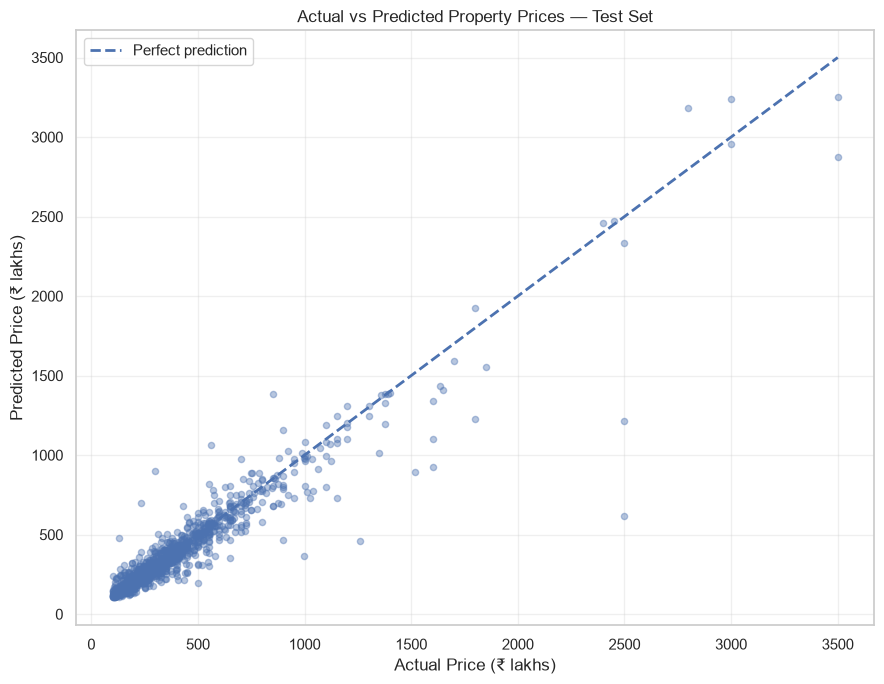

In [122]:
# G11.2: Actual vs Predicted Price Plot

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 7))

plt.scatter(
    error_df["actual_price_lakhs"],
    error_df["predicted_price_lakhs"],
    alpha=0.4,
    s=20
)

# Perfect prediction reference line
min_price = min(
    error_df["actual_price_lakhs"].min(),
    error_df["predicted_price_lakhs"].min()
)

max_price = max(
    error_df["actual_price_lakhs"].max(),
    error_df["predicted_price_lakhs"].max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

plt.xlabel("Actual Price (₹ lakhs)")
plt.ylabel("Predicted Price (₹ lakhs)")
plt.title("Actual vs Predicted Property Prices — Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [123]:
# G11.3: Find the 10 properties with the largest absolute errors

largest_errors = error_df.sort_values(
    by="absolute_error_lakhs",
    ascending=False
).head(10)

display(largest_errors.round(2))

,actual_price_lakhs,predicted_price_lakhs,error_lakhs,absolute_error_lakhs,absolute_percentage_error
370,2500.0,619.77,-1880.23,1880.23,75.21
393,2500.0,1213.44,-1286.56,1286.56,51.46
1164,1260.0,457.49,-802.51,802.51,63.69
112,1600.0,927.10,-672.90,672.90,42.06
1196,995.0,362.53,-632.47,632.47,63.57
842,1520.0,892.78,-627.22,627.22,41.26
1217,3500.0,2874.61,-625.39,625.39,17.87
1282,300.0,900.50,600.50,600.50,200.17
876,1800.0,1224.22,-575.78,575.78,31.99
635,850.0,1383.31,533.31,533.31,62.74


In [124]:
# Compare actual and predicted prices for the largest errors

print("Largest absolute error:")
print(
    f"₹{largest_errors['absolute_error_lakhs'].max():.2f} lakhs"
)

print("\nActual prices of the 10 worst predictions:")
print(largest_errors["actual_price_lakhs"].to_list())

print("\nPredicted prices of the 10 worst predictions:")
print(largest_errors["predicted_price_lakhs"].to_list())

Largest absolute error:
₹1880.23 lakhs

Actual prices of the 10 worst predictions:
[2500.0, 2500.0, 1260.0, 1600.0, 995.0, 1520.0, 3500.0, 300.0, 1800.0, 850.0]

Predicted prices of the 10 worst predictions:
[619.7664950238237, 1213.4382728749063, 457.49350891676147, 927.098945991476, 362.5281745582461, 892.7811189731634, 2874.6126881002488, 900.5035285284587, 1224.2234526196276, 1383.3111937570866]


In [125]:
# G11.4: Inspect the features of the 10 worst predictions

worst_indices = largest_errors.index

worst_features = full.loc[
    worst_indices,
    FINAL_CORE_FEATURES
].copy()

worst_features["actual_price_lakhs"] = (
    error_df.loc[worst_indices, "actual_price_lakhs"]
)

worst_features["predicted_price_lakhs"] = (
    error_df.loc[worst_indices, "predicted_price_lakhs"]
)

worst_features["absolute_error_lakhs"] = (
    error_df.loc[worst_indices, "absolute_error_lakhs"]
)

display(
    worst_features.sort_values(
        "absolute_error_lakhs",
        ascending=False
    ).round(3)
)

,bedroom_num,bathroom_num,balcony_num,floor_num,total_floor,total_landmark_count,area_sqft,property_type,owntype,furnish,facing,age,locality_grouped,latitude,longitude,actual_price_lakhs,predicted_price_lakhs,absolute_error_lakhs
370,3.0,3,2.0,3.0,4.0,46.0,1550.0,Independent/Builder Floor,1,4,1,6,DLF Phase 1,28.475,77.103,2500.0,619.766,1880.234
393,4.0,4,4.0,20.0,30.0,15.0,2721.0,Residential Apartment,1,4,5,1,Sector 54 Gurgaon,28.443,77.109,2500.0,1213.438,1286.562
1164,3.0,5,3.0,13.0,18.0,15.0,1950.0,Residential Apartment,1,0,0,6,Sector 70 Gurgaon,28.393,77.019,1260.0,457.494,802.506
112,4.0,4,3.0,14.0,17.0,6.0,2400.0,Residential Apartment,1,4,0,1,Sector 110 A Gurgaon,28.513,77.026,1600.0,927.099,672.901
1196,3.0,5,2.0,21.0,24.0,12.0,2343.0,Residential Apartment,1,2,3,6,Sector 108 Gurgaon,28.516,76.996,995.0,362.528,632.472
842,3.0,4,4.0,12.0,14.0,15.0,1859.0,Residential Apartment,1,4,3,2,Sector 49 Gurgaon,28.403,77.046,1520.0,892.781,627.219
1217,4.0,4,4.0,11.0,24.0,15.0,6400.0,Residential Apartment,1,4,3,2,Sector 42 Gurgaon,28.454,77.100,3500.0,2874.613,625.387
1282,3.0,3,2.0,7.0,14.0,8.0,1790.0,Residential Apartment,1,4,5,6,Sector-33 Sohna,28.420,77.038,300.0,900.504,600.504
876,3.0,3,3.0,9.0,15.0,10.0,1755.0,Residential Apartment,1,4,3,1,Sector 83 Gurgaon,28.397,76.969,1800.0,1224.223,575.777
635,4.0,4,4.0,1.0,17.0,48.0,2734.0,Residential Apartment,1,1,5,3,Sector 28 Gurgaon,28.476,77.074,850.0,1383.311,533.311


In [126]:
# Group test predictions by actual price range

price_bins = [0, 200, 400, 600, 1000, float("inf")]

price_labels = [
    "₹0–200L",
    "₹200–400L",
    "₹400–600L",
    "₹600–1000L",
    "Above ₹1000L"
]

error_df["price_range"] = pd.cut(
    error_df["actual_price_lakhs"],
    bins=price_bins,
    labels=price_labels,
    include_lowest=True
)

error_by_range = (
    error_df.groupby("price_range", observed=False)
    .agg(
        property_count=("actual_price_lakhs", "size"),
        mean_actual_price=("actual_price_lakhs", "mean"),
        MAE_lakhs=("absolute_error_lakhs", "mean"),
        median_absolute_error=("absolute_error_lakhs", "median"),
        mean_percentage_error=("absolute_percentage_error", "mean")
    )
    .round(2)
)

display(error_by_range)

,property_count,mean_actual_price,MAE_lakhs,median_absolute_error,mean_percentage_error
price_range,,,,,
₹0–200L,537,156.12,20.59,12.79,13.75
₹200–400L,572,285.20,31.87,19.67,11.11
₹400–600L,218,493.93,57.46,36.78,11.61
₹600–1000L,114,762.31,89.12,56.91,11.57
Above ₹1000L,51,1601.76,248.70,121.99,14.89


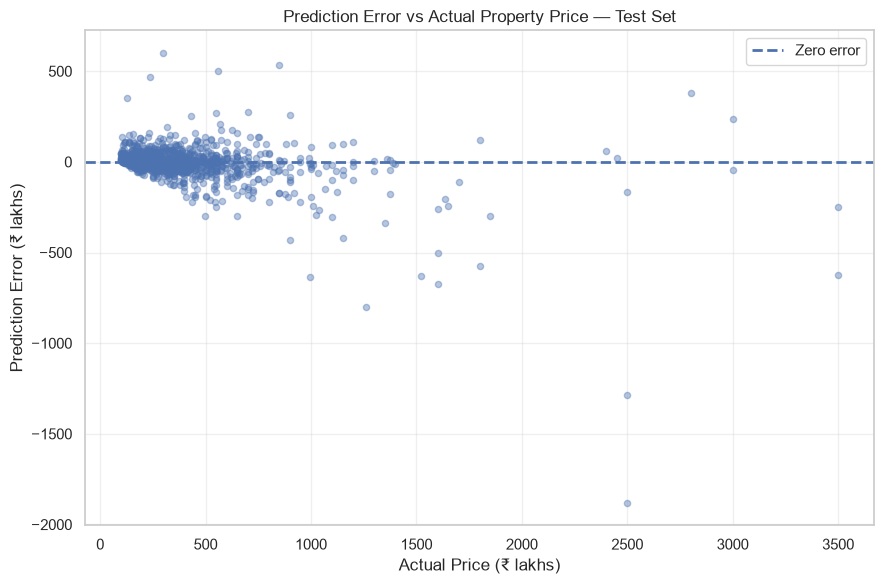

In [127]:
# G11.6: Prediction error versus actual price

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    error_df["actual_price_lakhs"],
    error_df["error_lakhs"],
    alpha=0.4,
    s=20
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=2,
    label="Zero error"
)

plt.xlabel("Actual Price (₹ lakhs)")
plt.ylabel("Prediction Error (₹ lakhs)")
plt.title("Prediction Error vs Actual Property Price — Test Set")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [128]:
from pathlib import Path

MODELS_DIR = Path("../models")

MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Models directory:", MODELS_DIR.resolve())

Models directory: D:\real-estate-price-prediction\models


In [129]:
MODELS_DIR = Path("models")

In [130]:
import joblib

MODEL_PATH = MODELS_DIR / "final_price_model.joblib"

joblib.dump(final_model, MODEL_PATH)

print("Final model saved successfully.")
print("Model path:", MODEL_PATH.resolve())
print("File size:", round(MODEL_PATH.stat().st_size / (1024 * 1024), 2), "MB")

FileNotFoundError: [Errno 2] No such file or directory: 'models\\final_price_model.joblib'

In [131]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

Current working directory:
d:\real-estate-price-prediction\notebooks


In [132]:
from pathlib import Path

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
MODELS_DIR = PROJECT_DIR / "models"

MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Models directory:", MODELS_DIR)
print("Directory exists:", MODELS_DIR.exists())

Models directory: D:\real-estate-price-prediction\models
Directory exists: True


In [133]:
import joblib

MODEL_PATH = MODELS_DIR / "final_price_model.joblib"

joblib.dump(final_model, MODEL_PATH)

print("Final model saved successfully!")
print("Model path:", MODEL_PATH)
print("File size:", round(MODEL_PATH.stat().st_size / (1024 * 1024), 2), "MB")

Final model saved successfully!
Model path: D:\real-estate-price-prediction\models\final_price_model.joblib
File size: 193.8 MB


In [134]:
import json

metadata = {
    "project": "Gurgaon Real Estate Price Prediction",
    "model_name": "RandomForestRegressor",
    "feature_set": "Core Model",
    "model_file": "final_price_model.joblib",
    "features": list(FINAL_FEATURES),
    "categorical_features": list(FINAL_CAT_FEATURES),
    "numerical_features": list(FINAL_NUM_FEATURES),
    "target": "log_price",
    "target_transformation": "log1p(price_lakhs)",
    "inverse_target_transformation": "expm1(predicted_log_price)",
    "training_rows": int(len(X_final_train)),
    "test_rows": int(len(X_test)),
    "random_state": 42,
    "best_hyperparameters": {
        key: value
        for key, value in BEST_RF_PARAMS.items()
    },
    "test_metrics_log_scale": {
        "r2": float(test_r2_log),
        "mae": float(test_mae_log),
        "rmse": float(test_rmse_log)
    },
    "test_metrics_original_price_scale_lakhs": {
        "r2": float(test_r2_lakhs),
        "mae_lakhs": float(test_mae_lakhs),
        "rmse_lakhs": float(test_rmse_lakhs)
    }
}

METADATA_PATH = MODELS_DIR / "final_model_metadata.json"

with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print("Metadata saved successfully!")
print("Metadata path:", METADATA_PATH)

NameError: name 'FINAL_CAT_FEATURES' is not defined

In [135]:
# Define categorical and numerical features for the final model

FINAL_FEATURES = FINAL_CORE_FEATURES.copy()

FINAL_CAT_FEATURES = [
    col for col in FINAL_FEATURES
    if col in BASE_CAT
]

FINAL_NUM_FEATURES = [
    col for col in FINAL_FEATURES
    if col not in FINAL_CAT_FEATURES
]

print("Total features:", len(FINAL_FEATURES))
print("Categorical features:", len(FINAL_CAT_FEATURES))
print("Numerical features:", len(FINAL_NUM_FEATURES))

print("\nCategorical columns:")
print(FINAL_CAT_FEATURES)

print("\nNumerical columns:")
print(FINAL_NUM_FEATURES)

assert len(FINAL_FEATURES) == 15
assert len(FINAL_CAT_FEATURES) == 6
assert len(FINAL_NUM_FEATURES) == 9

Total features: 15
Categorical features: 6
Numerical features: 9

Categorical columns:
['property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']

Numerical columns:
['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude']


In [136]:
import json

metadata = {
    "project": "Gurgaon Real Estate Price Prediction",
    "model_name": "RandomForestRegressor",
    "feature_set": "Core Model",
    "model_file": "final_price_model.joblib",
    "features": list(FINAL_FEATURES),
    "categorical_features": list(FINAL_CAT_FEATURES),
    "numerical_features": list(FINAL_NUM_FEATURES),
    "target": "log_price",
    "target_transformation": "log1p(price_lakhs)",
    "inverse_target_transformation": "expm1(predicted_log_price)",
    "training_rows": int(len(X_final_train)),
    "test_rows": int(len(X_test)),
    "random_state": 42,
    "best_hyperparameters": {
        key: value
        for key, value in BEST_RF_PARAMS.items()
    },
    "test_metrics_log_scale": {
        "r2": float(test_r2_log),
        "mae": float(test_mae_log),
        "rmse": float(test_rmse_log)
    },
    "test_metrics_original_price_scale_lakhs": {
        "r2": float(test_r2_lakhs),
        "mae_lakhs": float(test_mae_lakhs),
        "rmse_lakhs": float(test_rmse_lakhs)
    }
}

METADATA_PATH = MODELS_DIR / "final_model_metadata.json"

with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print("Metadata saved successfully!")
print("Metadata path:", METADATA_PATH)

Metadata saved successfully!
Metadata path: D:\real-estate-price-prediction\models\final_model_metadata.json


In [137]:
import joblib

loaded_model = joblib.load(MODEL_PATH)

print("Model loaded successfully!")
print("Model type:", type(loaded_model).__name__)
print("Expected input features:", len(FINAL_FEATURES))

Model loaded successfully!
Model type: Pipeline
Expected input features: 15


In [138]:
import numpy as np

loaded_predictions_log = loaded_model.predict(X_test)

max_difference = np.max(
    np.abs(test_predictions_log - loaded_predictions_log)
)

print("Maximum prediction difference:", max_difference)

assert np.allclose(
    test_predictions_log,
    loaded_predictions_log
), "Prediction mismatch!"

print("PASS: Saved model reproduces the original predictions.")

Maximum prediction difference: 5.329070518200751e-15
PASS: Saved model reproduces the original predictions.


In [139]:
import pandas as pd

final_results = pd.DataFrame([
    {
        "Metric": "R²",
        "Log Scale": test_r2_log,
        "Original Price Scale": test_r2_lakhs
    },
    {
        "Metric": "MAE",
        "Log Scale": test_mae_log,
        "Original Price Scale": test_mae_lakhs
    },
    {
        "Metric": "RMSE",
        "Log Scale": test_rmse_log,
        "Original Price Scale": test_rmse_lakhs
    }
])

display(final_results.round(4))

,Metric,Log Scale,Original Price Scale
0,R²,0.9123,0.9023
1,MAE,0.1184,43.3377
2,RMSE,0.1827,100.1483


In [140]:
print("FINAL_CORE_FEATURES:", len(FINAL_CORE_FEATURES))
print("FINAL_FEATURES:", len(FINAL_FEATURES))

print("\nFinal model features:")
print(FINAL_FEATURES)

print("\nCategorical features:")
print(FINAL_CAT_FEATURES)

print("\nNumerical features:")
print(FINAL_NUM_FEATURES)

print("\nFull dataset shape:", full.shape)
print("Training rows:", len(train_idx))
print("Test rows:", len(test_idx))

FINAL_CORE_FEATURES: 15
FINAL_FEATURES: 15

Final model features:
['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped', 'latitude', 'longitude']

Categorical features:
['property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']

Numerical features:
['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude']

Full dataset shape: (7457, 45)
Training rows: 5965
Test rows: 1492


In [141]:
from pathlib import Path

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Use the exact features from the saved final model
final_features = FINAL_FEATURES.copy()
final_num = FINAL_NUM_FEATURES.copy()
final_cat = FINAL_CAT_FEATURES.copy()

# Keep the model features, target columns, and property ID
keep_cols = ["prop_id"] + final_features + [
    "price_lakhs",
    "log_price"
]

model_data = full[keep_cols].copy()

# Preserve the original train/test split
model_data["split"] = "train"
model_data.loc[test_idx, "split"] = "test"

# Save
MODEL_DATA_PATH = PROCESSED_DIR / "model_data.csv"
model_data.to_csv(MODEL_DATA_PATH, index=False)

print("Saved:", MODEL_DATA_PATH)
print("Shape:", model_data.shape)
print("Split counts:")
print(model_data["split"].value_counts())

Saved: D:\real-estate-price-prediction\data\processed\model_data.csv
Shape: (7457, 19)
Split counts:
split
train    5965
test     1492
Name: count, dtype: int64


In [142]:
variables_to_check = [
    "groups",
    "ACC_COLS",
    "access_params",
    "WEIGHTS",
    "SCORE",
    "edges",
    "density_params",
    "COUNT_BASES",
    "AGE_MAP",
]

for name in variables_to_check:
    print(f"{name}: {'Available' if name in globals() else 'NOT DEFINED'}")

groups: Available
ACC_COLS: Available
access_params: Available
WEIGHTS: Available
SCORE: Available
edges: Available
density_params: Available
COUNT_BASES: Available
AGE_MAP: NOT DEFINED
